# Weekly Fantasy Football Rankings vs. the Experts
CS 363M final project. Hassaan Ali, Shyamal Gupta, Amin Momin.

## 1. Introduction
**Main task:** predict each QB/RB/WR/TE's PPR fantasy points for the coming week using only pre-game info, rank players by those predictions, and compare the rankings to the FantasyPros expert consensus (ECR).

**Data:** eight public sources from nflverse, loaded with `nflreadpy` for the 2019-2025 regular seasons:
- **Player stats:** each player's weekly box score and PPR points (the target).
- **Snap counts:** share of the team's offensive snaps each player was on the field for.
- **Weekly rosters:** team, position, and roster status (active, injured reserve, and so on) each week.
- **Schedules:** games, home and away, and the Vegas point spread and total.
- **Expected fantasy points:** points a player's touches were worth on average, given where on the field they happened.
- **Injury reports:** the official game status (out, doubtful, questionable) teams publish before each game.
- **Player ID map:** links each source's player IDs to one ID (`gsis_id`).
- **Expert rankings (ECR):** FantasyPros weekly consensus ranks, used only to compare against, never as a model feature.

2019 is used only for warm-up lags, 2020-2024 for training and cross-validation, and 2025 is the held-out test set, used once at the end with every setting frozen.

**Recency:** next week depends most on a player's current role, team, and health, so recent games get more weight. How much more is tuned with cross-validation: recency-weighted features, training weights that fade with a game's age, and a 2025 test that refits each week on all games before it.

**Results in short:**
- **Model (section 6):** a voting ensemble of Lasso, gradient boosting, and an MLP. In cross-validation it gets RMSE 6.77 and Spearman 0.525, against 6.81 and 0.515 for a plain Ridge and 7.59 and 0.423 for a last-3-games average.
- **2025 test (section 9):** RMSE 6.83 and Spearman 0.505, close to the CV scores. Against the experts on the same 3,025 player-weeks we lose on ranking by a small, consistent margin (Spearman 0.489 vs. 0.512) and are slightly ahead on top-12 hit rate (0.526 vs. 0.514).
- **Tiers (section 7):** tiers cut from the regression beat a direct tier classifier (macro F1 0.495 vs. 0.454).
- **Usage clusters (section 8):** four usage profiles describe player roles but do not improve the regression.

**How to read this notebook:**
- Sections 3 to 5 build the data: clean tables, exploration, and the 48 pre-game features.
- Section 6 picks the model and section 9 tests it on 2025. Together they are the main task.
- Sections 7 and 8 are the two extensions. They sit between 6 and 9 because they use only 2020-2024.
- Section 10 explains the results and lists what we tried and dropped.
- Each step ends with a **What we see** note. Reading only those notes gives the whole story.

## 2. Setup and config
Imports, then one config cell with every setting that later sections share. The model grids sit next to the models they tune (6.2 and 7.2).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nflreadpy as nfl

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
# Config: every tunable setting lives here.
SEED = 363
POSITIONS = ["QB", "RB", "WR", "TE"]
WARMUP_SEASON = 2019             # lags only, never a target row
TRAIN_SEASONS = list(range(2020, 2025))
TEST_SEASON = 2025               # used once, in the final test section
ALL_SEASONS = [WARMUP_SEASON] + TRAIN_SEASONS + [TEST_SEASON]
TARGET = "fantasy_points_ppr"

# Player pool: who we model in week t, decided from games before t only.
POOL_LOOKBACK_GAMES = 3          # look at the player's last N games played
POOL_MIN_SNAP_SHARE = 0.40       # mean offensive snap share over those games
ECR_PAGES = {"weekly-qb": "QB", "weekly-rb": "RB", "weekly-wr": "WR", "weekly-te": "TE"}  # PPR weekly pages

# Features and evaluation
HALF_LIFE_CANDIDATES = [3, 5, 8, 12, 16]  # games; recency weight halves every N games (picked by CV)
PLAIN_WINDOW_GAMES = 8            # the equal-weight version recency has to beat
LUCK_HALF_LIFE_GAMES = 16         # luck evens out slowly, so it gets a longer memory
CV_VALID_SEASONS = [2022, 2023, 2024]  # expanding window: train on every season before each
TOP_N = 12                        # "did our top 12 finish top 12" per position-week

# Points regression (section 6)
SELECT_METRIC = "spearman"                      # models are picked on rank quality; RMSE is reported next to it
TRAIN_WINDOW_CANDIDATES = [None, 3, 2, 1]       # seasons of history to train on; None = all (picked by CV)
WEIGHT_HALF_LIFE_CANDIDATES = [None, 4, 2, 1]   # seasons; a game's training weight halves every N; None = equal (picked by CV)
WEEKS_PER_SEASON = 18

# Tiers (section 7)
TIER_CUTS = [12, 24]              # tier 1 = position rank 1-12, tier 2 = 13-24, tier 3 = the rest

# Usage clustering (section 8)
CLUSTER_K_CANDIDATES = [3, 4, 5, 6]     # numbers of usage profiles to try (K-Means and Ward)
CLUSTER_SAMPLE_SIZE = 2500              # player-weeks sampled to compare the clustering methods
DBSCAN_EPS_CANDIDATES = [0.5, 1.0]      # neighborhood radius, in standardized units
DBSCAN_MIN_SAMPLES = 20                 # neighbors a point needs to be a core point

# Final test (section 9)
EARLY_SEASON_WEEKS = 4            # "early season" = weeks 1 to N
RETURN_GAP_WEEKS = 3              # "back from absence" = N or more weeks since the last game
BOOTSTRAP_DRAWS = 5000            # resamples of the weekly gap to the experts, for the verdict

# Analysis (section 10)
SHUFFLE_REPEATS = 3               # shuffles per feature group when measuring what drives predictions
DISAGREE_GAPS = [6, 9, 12]        # position-rank places apart that count as a disagreement with the experts
RELEVANT_RANK = 24                # a disagreement counts only if one side ranks the player in its top N

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
for d in (RAW_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)

## 3. Load and clean

Goal: one clean table with one row per player per week. Steps:
1. Download each source once and cache it in `data/raw/`.
2. Standardize team codes and map every source to one player ID (`gsis_id`).
3. Build every regular-season game a QB/RB/WR/TE played (`player_games`), the history all later lags use.
4. Pick the player pool for each week using only earlier games, then drop players who did not play.
5. Attach Vegas lines and expected points, and match each expert (ECR) snapshot to the right week.
6. Run an anomaly-detection pass to separate data errors from real big games.

In [3]:
def load_cached(name, loader):
    """Load a source from data/raw/ if cached, otherwise download it with nflreadpy and cache it."""
    path = RAW_DIR / f"{name}.parquet"
    if not path.exists():
        loader().write_parquet(path)
    return pd.read_parquet(path)


raw = {
    "stats": load_cached("player_stats", lambda: nfl.load_player_stats(ALL_SEASONS)),
    "snaps": load_cached("snap_counts", lambda: nfl.load_snap_counts(ALL_SEASONS)),
    "rosters": load_cached("rosters_weekly", lambda: nfl.load_rosters_weekly(ALL_SEASONS)),
    "schedules": load_cached("schedules", lambda: nfl.load_schedules(ALL_SEASONS)),
    "opportunity": load_cached("ff_opportunity", lambda: nfl.load_ff_opportunity(ALL_SEASONS)),
    "ids": load_cached("ff_playerids", nfl.load_ff_playerids),
    "ecr": load_cached("ff_rankings", lambda: nfl.load_ff_rankings("all")),
}
pd.DataFrame({name: df.shape for name, df in raw.items()}, index=["rows", "cols"]).T

,rows,cols
stats,129812,150
snaps,181478,16
rosters,327704,36
schedules,1960,46
opportunity,41696,159
ids,12541,35
ecr,1885069,24


### 3.1 Team codes and player IDs
The nflverse sources agree on team codes except `OAK` (2019). FantasyPros uses older codes (`JAC`, `LAR`, `SD`, `STL`).
Every source is mapped to the NFL `gsis_id`. Snap counts use Pro Football Reference IDs and ECR uses FantasyPros IDs,
so we translate them with the weekly rosters and the ffverse ID crosswalk.

In [4]:
TEAM_FIXES = {"OAK": "LV", "JAC": "JAX", "LAR": "LA", "STL": "LA", "SD": "LAC", "FA": None, "": None}


def fix_team(codes):
    return codes.replace(TEAM_FIXES)


def id_map(pairs, from_col):
    """One gsis_id per foreign ID; drop foreign IDs that point to more than one player."""
    pairs = pairs.dropna().drop_duplicates()
    pairs = pairs[~pairs[from_col].duplicated(keep=False)]
    return pairs.set_index(from_col)["gsis_id"]


ids = raw["ids"].assign(fantasypros_id=lambda d: d["fantasypros_id"].astype("Int64").astype("string"))  # stored as float
rosters = raw["rosters"]
pfr_to_gsis = id_map(pd.concat([rosters[["pfr_id", "gsis_id"]], ids[["pfr_id", "gsis_id"]]]), "pfr_id")
fp_to_gsis = id_map(ids[["fantasypros_id", "gsis_id"]], "fantasypros_id")
print(f"PFR IDs mapped: {len(pfr_to_gsis):,}   FantasyPros IDs mapped: {len(fp_to_gsis):,}")

PFR IDs mapped: 7,853   FantasyPros IDs mapped: 4,782


**What we see:** 7,853 Pro Football Reference IDs and 4,782 FantasyPros IDs map to exactly one `gsis_id`. IDs that point to more than one player are dropped, so a bad match can never merge two players' stats.

### 3.2 Every game each QB/RB/WR/TE played
A player "played" a game if the player took an offensive snap or recorded any stat. Players who played but had no stat line
score 0. This table is the history that the player pool and every lag feature are built from.

In [5]:
def regular_season(df, col="season_type"):
    return df[df[col] == "REG"]


def build_snaps(snaps):
    snaps = regular_season(snaps, "game_type").copy()
    snaps["gsis_id"] = snaps["pfr_player_id"].map(pfr_to_gsis)
    snaps["team"] = fix_team(snaps["team"])
    keep = ["gsis_id", "season", "week", "team", "offense_snaps", "offense_pct"]
    return snaps.dropna(subset=["gsis_id"])[keep].sort_values("offense_snaps").drop_duplicates(["gsis_id", "season", "week"], keep="last")


def build_player_games(stats, snaps, rosters):
    stats = regular_season(stats).rename(columns={"player_id": "gsis_id"})
    stats["team"] = fix_team(stats["team"])
    key = ["gsis_id", "season", "week"]
    games = stats.merge(snaps, on=key, how="outer", suffixes=("", "_snap"))
    games["team"] = games["team"].fillna(games["team_snap"])
    # Position from that week's roster, falling back to the stats feed.
    pos = regular_season(rosters, "game_type")[key + ["position"]].drop_duplicates(key)
    games = games.merge(pos, on=key, how="left", suffixes=("_stats", ""))
    games["position"] = games["position"].fillna(games["position_stats"])
    played = games["offense_snaps"].fillna(0).gt(0) | games["fantasy_points_ppr"].notna()
    games = games[played & games["position"].isin(POSITIONS)].copy()
    games[TARGET] = games[TARGET].fillna(0.0)
    return games.drop(columns=["team_snap", "position_stats"])


snaps = build_snaps(raw["snaps"])
player_games = build_player_games(raw["stats"], snaps, rosters)
print(f"{len(player_games):,} player-games;  with a snap record: {player_games['offense_snaps'].notna().mean():.1%};"
      f"  with a stat line: {player_games['player_name'].notna().mean():.1%}")
player_games.groupby(["season", "position"]).size().unstack()

46,945 player-games;  with a snap record: 99.8%;  with a stat line: 87.4%


position,QB,RB,TE,WR
season,,,,
2019,614,1707,1407,2493
2020,649,1757,1504,2590
2021,689,1785,1625,2777
2022,654,1812,1645,2704
2023,698,1703,1612,2811
2024,682,1721,1678,2751
2025,687,1759,1666,2765


**What we see:** 46,945 played games from 2019 to 2025, about 6,700 per season. 99.8% have a snap record.
12.6% have no stat line (mostly blocking snaps), and those score 0.

### 3.3 Game context and expected points
Each game gets its Vegas lines (from the schedule) and the player's expected PPR points (ffopportunity).
ffopportunity only lists players who had a pass, carry, or target, so a missing row means zero expected points.

In [6]:
def build_team_games(schedules):
    """One row per team per regular-season game, with the Vegas lines from that team's side."""
    s = regular_season(schedules, "game_type").copy()
    s["kickoff"] = pd.to_datetime(s["gameday"] + " " + s["gametime"].fillna("13:00"))
    common = ["game_id", "season", "week", "kickoff", "total_line"]
    home = s[common + ["home_team", "away_team", "spread_line"]].rename(columns={"home_team": "team", "away_team": "opponent"})
    away = s[common + ["away_team", "home_team", "spread_line"]].rename(columns={"away_team": "team", "home_team": "opponent"})
    home["is_home"], away["is_home"] = 1, 0
    away["spread_line"] = -away["spread_line"]   # nflverse spread_line is points the home team is favored by
    games = pd.concat([home, away]).rename(columns={"spread_line": "team_favored_by", "game_id": "sched_game_id"})
    for col in ("team", "opponent"):
        games[col] = fix_team(games[col])
    return games


def build_expected_points(opportunity):
    o = opportunity.rename(columns={"player_id": "gsis_id"}).dropna(subset=["gsis_id"])
    o = o.astype({"season": int, "week": int})
    return o[["gsis_id", "season", "week", "total_fantasy_points", "total_fantasy_points_exp"]].rename(
        columns={"total_fantasy_points": "pbp_points", "total_fantasy_points_exp": "expected_points"})


team_games = build_team_games(raw["schedules"])
expected = build_expected_points(raw["opportunity"])
player_games = (player_games
                .merge(team_games, on=["season", "week", "team"], how="left", validate="many_to_one")
                .merge(expected, on=["gsis_id", "season", "week"], how="left", validate="one_to_one"))
player_games["has_expected_points"] = player_games["expected_points"].notna()
player_games["expected_points"] = player_games["expected_points"].fillna(0.0)
print(f"Matched to a scheduled game: {player_games['sched_game_id'].notna().mean():.2%};"
      f"  has an ffopportunity row: {player_games['has_expected_points'].mean():.1%}")

Matched to a scheduled game: 100.00%;  has an ffopportunity row: 78.6%


**What we see:** every game matches a scheduled game, so every row gets its Vegas lines. 78.6% have an ffopportunity row; the other 21.4% had no pass, carry, or target, so their expected points are 0.

### 3.4 Anomaly detection: data errors vs. real big games
- **Rule checks** find rows that cannot be right: reported PPR points that disagree with the box score,
  more receptions than targets, or touches with zero offensive snaps. These are data errors and are dropped.
- **Cross-source check:** ffopportunity recomputes actual points from play-by-play, an independent source.
  We compare it to the official box score after removing return TDs (not scored by ffopportunity) and whole
  multiples of 2 points (fumble and 2-point conversion scoring differences).
- **Isolation Forest** flags rows that are unusual given points, snap share, and opportunities.
  A row flagged only here is a real big (or very bad) game and is kept.

In [7]:
def rebuild_ppr(g):
    f = g.select_dtypes("number").fillna(0)
    return (0.04 * f["passing_yards"] + 4 * f["passing_tds"] - 2 * f["passing_interceptions"]
            + 0.1 * (f["rushing_yards"] + f["receiving_yards"]) + 6 * (f["rushing_tds"] + f["receiving_tds"])
            + f["receptions"] + 2 * (f["passing_2pt_conversions"] + f["rushing_2pt_conversions"] + f["receiving_2pt_conversions"])
            - 2 * (f["sack_fumbles_lost"] + f["rushing_fumbles_lost"] + f["receiving_fumbles_lost"])
            + 6 * f["special_teams_tds"])


def opportunities(g):
    return g["attempts"].fillna(0) + g["carries"].fillna(0) + g["targets"].fillna(0)


def rule_flags(g):
    return pd.DataFrame({
        "points_mismatch": (rebuild_ppr(g) - g[TARGET]).abs() > 0.5,
        "receptions_gt_targets": g["receptions"].fillna(0) > g["targets"].fillna(0),
        "touches_no_snaps": g["offense_snaps"].eq(0) & opportunities(g).gt(0),
    }, index=g.index)


def cross_source_gap(g):
    """Box-score points minus play-by-play points, after known scoring-rule differences."""
    gap = g[TARGET] - 6 * g["special_teams_tds"].fillna(0) - g["pbp_points"]
    scoring_rule = (gap / 2 - (gap / 2).round()).abs() < 0.01
    return gap.where(~scoring_rule, 0.0)


def isolation_flags(g):
    from sklearn.ensemble import IsolationForest
    X = pd.DataFrame({"points": g[TARGET], "snap_pct": g["offense_pct"].fillna(0), "opportunities": opportunities(g)})
    model = IsolationForest(contamination=0.01, random_state=SEED).fit(X)
    return pd.Series(model.predict(X) == -1, index=g.index)


rules = rule_flags(player_games)
player_games["data_error"] = rules.any(axis=1)
player_games["isolation_outlier"] = isolation_flags(player_games)
gap = cross_source_gap(player_games).dropna()

display(rules.sum().rename("rows flagged").to_frame())
print(f"Cross-source: {(gap.abs() <= 1).mean():.2%} of {len(gap):,} games agree within 1 point; "
      f"{(gap.abs() > 1).sum()} differ by more than 1, {(gap.abs() > 5).sum()} by more than 5.")
display(pd.crosstab(player_games["isolation_outlier"], player_games["data_error"],
                    rownames=["isolation outlier"], colnames=["data error"]))
show = ["player_display_name", "position", "season", "week", TARGET, "offense_pct", "carries", "targets"]
display(player_games[player_games["isolation_outlier"]].nlargest(5, TARGET)[show])
display(player_games[player_games["data_error"]][show])

,rows flagged
points_mismatch,0
receptions_gt_targets,0
touches_no_snaps,12


Cross-source: 99.85% of 36,876 games agree within 1 point; 56 differ by more than 1, 3 by more than 5.


data error,False,True
isolation outlier,,
False,46463,12
True,470,0


,player_display_name,position,season,week,fantasy_points_ppr,offense_pct,carries,targets
10675,Tyreek Hill,WR,2020,12,57.9,0.86,0.0,15.0
16008,Alvin Kamara,RB,2020,16,56.2,0.60,22.0,5.0
35171,Ja'Marr Chase,WR,2021,17,55.6,0.91,0.0,12.0
35210,Ja'Marr Chase,WR,2024,10,55.4,0.94,0.0,17.0
43719,Jahmyr Gibbs,RB,2025,12,55.4,0.74,15.0,12.0


,player_display_name,position,season,week,fantasy_points_ppr,offense_pct,carries,targets
3745,Giovani Bernard,RB,2022,15,0.00,0.0,1.0,0.0
5247,AJ McCarron,QB,2020,17,0.80,0.0,0.0,0.0
11358,Mike Thomas,WR,2019,15,1.50,0.0,0.0,1.0
19572,Logan Woodside,QB,2020,11,0.28,0.0,0.0,0.0
20063,Godwin Igwebuike,RB,2021,18,0.00,0.0,0.0,1.0
25375,Michael Walker,WR,2019,14,1.90,0.0,0.0,1.0
26241,Travis Homer,RB,2019,13,2.90,0.0,1.0,0.0
29107,Nick Westbrook-Ikhine,WR,2020,11,1.70,0.0,0.0,1.0
34469,Kene Nwangwu,RB,2021,9,6.90,0.0,1.0,0.0
35419,Jacob Harris,WR,2022,12,1.60,0.0,0.0,1.0


**What we see:**
- The reported PPR points match the box score on every row. The only data errors are 12 games with a carry or target but 0 offensive snaps (a bad snap record), and we drop them.
- The independent play-by-play source agrees within 1 point on 99.85% of 36,876 games. Only 3 differ by more than 5 points (largest: Jameson Williams, 2024 week 17, 10.1 points). We keep the official box score as the target.
- Isolation Forest flags 470 games (1%), and none breaks a rule. They are real extremes, like Tyreek Hill's 57.9 points (2020 week 12) and very poor QB games, so we keep them.

### 3.5 Player pool: who we model each week
A player is in the week-*t* pool if, over their last 3 games played **before** week *t* (crossing seasons if needed),
they averaged at least 40% of their team's offensive snaps, and their team plays in week *t*. This uses only past games.
Pool players who then did not play (inactive or ruled out) are dropped; inactive lists are public before kickoff.

In [8]:
def add_pool_snap_share(candidates, games):
    """Mean snap share over each player's last N games strictly before the candidate week."""
    hist = games.sort_values(["season", "week"]).copy()
    hist["recent_snap_share"] = (hist.groupby("gsis_id")["offense_pct"]
                                 .transform(lambda s: s.fillna(0).rolling(POOL_LOOKBACK_GAMES, min_periods=1).mean()))
    hist["order"] = hist["season"] * 100 + hist["week"]
    candidates = candidates.assign(order=candidates["season"] * 100 + candidates["week"]).sort_values("order")
    return pd.merge_asof(candidates, hist[["gsis_id", "order", "recent_snap_share"]].sort_values("order"),
                         on="order", by="gsis_id", allow_exact_matches=False).drop(columns="order")


def build_candidates(rosters, games):
    """Every QB/RB/WR/TE on a roster (or who played) in a target-season week."""
    key = ["gsis_id", "season", "week"]
    r = regular_season(rosters, "game_type")
    r = r[r["position"].isin(POSITIONS)].dropna(subset=["gsis_id"]).assign(team=lambda d: fix_team(d["team"]))
    cand = pd.concat([r[key + ["team", "position", "status"]], games[key + ["team", "position"]]]).drop_duplicates(key)
    return cand[cand["season"] >= TRAIN_SEASONS[0]]


candidates = add_pool_snap_share(build_candidates(rosters, player_games), player_games)
team_has_game = candidates.set_index(["season", "week", "team"]).index.isin(team_games.set_index(["season", "week", "team"]).index)
played_keys = player_games.set_index(["gsis_id", "season", "week"]).index
candidates = candidates.assign(
    team_has_game=team_has_game,
    has_history=candidates["recent_snap_share"].notna(),
    in_pool=team_has_game & candidates["recent_snap_share"].ge(POOL_MIN_SNAP_SHARE),
    played=candidates.set_index(["gsis_id", "season", "week"]).index.isin(played_keys),
)
STATUS_GROUPS = {"ACT": "active", "INA": "game-day inactive", "RES": "injured reserve"}
pool = candidates[candidates["in_pool"]]
reason = pool["status"].map(STATUS_GROUPS).fillna("other (practice squad, cut, suspended)")
display(pd.crosstab(reason, pool["played"], margins=True).rename(columns={True: "played", False: "did not play"}))
display(pool.groupby("position")["played"].agg(pool_rows="size", played_share="mean").round(3))

played,did not play,played,All
status,,,
active,1311,22145,23456
game-day inactive,2446,0,2446
injured reserve,2815,0,2815
"other (practice squad, cut, suspended)",2007,0,2007
All,8579,22145,30724


,pool_rows,played_share
position,,
QB,6470,0.527
RB,4922,0.802
TE,6210,0.812
WR,13122,0.743


**What we see:** 30,724 pool player-weeks, and 22,145 (72%) played.
- Every pool player who was game-day inactive (2,446), on injured reserve (2,815), or on the practice squad or cut (2,007) did not play, so roster status lines up with playing.
- Of the 1,311 active players who did not play, 1,209 are QBs: benched starters who are still on the roster. That is why only 53% of the QB pool played, versus 74-81% for the other positions.

### 3.6 Expert rankings (ECR): match each snapshot to a week
FantasyPros posts weekly PPR rankings on Fridays. A snapshot belongs to the first week whose last game is on or after the
snapshot date; if a week has several snapshots we keep the latest. Players whose game kicked off on or before the snapshot date
(Thursday games, international games) are marked `played_before_snapshot` and left out of the expert comparison.
ECR is saved in its own file so it can never become a model feature.

In [9]:
def week_windows(schedules):
    s = regular_season(schedules, "game_type").assign(gameday=lambda d: pd.to_datetime(d["gameday"]))
    return s.groupby(["season", "week"])["gameday"].agg(first_game="min", last_game="max").reset_index()


def build_ecr(ecr, windows):
    e = ecr[ecr["page_type"].isin(ECR_PAGES) & (ecr["ecr_type"] == "wp")].copy()
    e["position"] = e["page_type"].map(ECR_PAGES)
    e["snapshot_date"] = pd.to_datetime(e["scrape_date"])
    e["gsis_id"] = e["id"].astype("string").map(fp_to_gsis)
    # Snapshot -> first week whose last game is on or after the snapshot date.
    snaps_dates = pd.DataFrame({"snapshot_date": e["snapshot_date"].drop_duplicates().sort_values()})
    wk = pd.merge_asof(snaps_dates, windows.sort_values("last_game"), left_on="snapshot_date",
                       right_on="last_game", direction="forward")
    wk = wk[wk["snapshot_date"] >= wk["first_game"] - pd.Timedelta(days=7)]   # drop preseason/offseason snapshots
    e = e.merge(wk[["snapshot_date", "season", "week"]].astype({"season": int, "week": int}), on="snapshot_date")
    latest = e.groupby(["season", "week", "position"])["snapshot_date"].transform("max")
    e = e[e["snapshot_date"] == latest]
    e["ecr_pos_rank"] = e.groupby(["season", "week", "position"])["ecr"].rank(method="first")
    return e[["gsis_id", "season", "week", "position", "player", "ecr", "ecr_pos_rank", "sd", "snapshot_date"]]


ecr_all = build_ecr(raw["ecr"], week_windows(raw["schedules"]))
ecr_all = ecr_all[ecr_all["season"].isin(TRAIN_SEASONS + [TEST_SEASON])]
print(f"ECR rows: {len(ecr_all):,};  mapped to a gsis_id: {ecr_all['gsis_id'].notna().mean():.1%}")
display(ecr_all.groupby("season")["week"].agg(weeks_covered="nunique", first_week="min", last_week="max"))

ECR rows: 38,690;  mapped to a gsis_id: 99.7%


,weeks_covered,first_week,last_week
season,,,
2020,11,6,16
2021,17,1,17
2022,16,2,17
2023,16,2,17
2024,14,4,17
2025,16,2,17


**What we see:**
- 99.7% of ECR rows map to a gsis_id.
- The archive covers 11 to 17 weeks a season and never week 18. 2020 starts at week 6 and 2024 at week 4, so the expert comparison only uses weeks with a snapshot.
- Training uses every week.

### 3.7 Final tables, rows kept at each step, and join rates
Join the player pool to the played games to get the modeling table, mark which expert ranks were made before kickoff,
then count the rows kept at each step and how well each source joins.

In [10]:
def build_player_weeks(games, cands):
    pool = cands.loc[cands["in_pool"], ["gsis_id", "season", "week", "recent_snap_share"]]
    weeks = games.merge(pool, on=["gsis_id", "season", "week"], how="inner")
    return weeks[~weeks["data_error"]].reset_index(drop=True)


def attach_ecr_flags(ecr, weeks):
    """Keep ECR rows for pool players and mark games that kicked off before the snapshot."""
    e = ecr.dropna(subset=["gsis_id"]).drop_duplicates(["gsis_id", "season", "week"])
    e = e.merge(weeks[["gsis_id", "season", "week", "kickoff"]], on=["gsis_id", "season", "week"], how="inner")
    e["played_before_snapshot"] = e["kickoff"].dt.normalize() <= e["snapshot_date"]
    return e.drop(columns="kickoff")


player_weeks = build_player_weeks(player_games, candidates)
ecr_weekly = attach_ecr_flags(ecr_all, player_weeks)

c = candidates
steps = pd.Series({
    "QB/RB/WR/TE on a roster or played, 2020-2025 regular season": len(c),
    "team has a game that week (drop byes)": c["team_has_game"].sum(),
    "has at least one earlier game": (c["team_has_game"] & c["has_history"]).sum(),
    f"recent snap share >= {POOL_MIN_SNAP_SHARE:.0%} (player pool)": c["in_pool"].sum(),
    "played (drop inactive / ruled out)": (c["in_pool"] & c["played"]).sum(),
    "not a data error (final)": len(player_weeks),
}, name="rows")
display(steps.to_frame())

ecr_weeks = player_weeks.merge(ecr_all[["season", "week"]].drop_duplicates(), on=["season", "week"])
ecr_ranked = ecr_all.dropna(subset=["gsis_id"])
top_ranked = ecr_ranked[ecr_ranked["ecr_pos_rank"] <= ecr_ranked["position"].map({"QB": 12, "RB": 24, "WR": 36, "TE": 12})]
join_rates = pd.Series({
    "snap counts": player_weeks["offense_snaps"].notna().mean(),
    "box-score stats": player_weeks["player_name"].notna().mean(),
    "schedule and Vegas lines": player_weeks["total_line"].notna().mean(),
    "ffopportunity (expected points)": player_weeks["has_expected_points"].mean(),
    "ECR: ECR rows mapped to a gsis_id": ecr_all["gsis_id"].notna().mean(),
    "ECR: pool rows (in ECR weeks) with an ECR rank": ecr_weeks.set_index(["gsis_id", "season", "week"]).index.isin(
        ecr_weekly.set_index(["gsis_id", "season", "week"]).index).mean(),
    "ECR: startable ECR players (QB12/RB24/WR36/TE12) in our pool": top_ranked.set_index(["gsis_id", "season", "week"]).index.isin(
        player_weeks.set_index(["gsis_id", "season", "week"]).index).mean(),
}, name="join rate")
display(join_rates.map("{:.1%}".format).to_frame())

,rows
"QB/RB/WR/TE on a roster or played, 2020-2025 regular season",81291
team has a game that week (drop byes),81146
has at least one earlier game,68002
recent snap share >= 40% (player pool),30724
played (drop inactive / ruled out),22145
not a data error (final),22145


,join rate
snap counts,100.0%
box-score stats,95.5%
schedule and Vegas lines,100.0%
ffopportunity (expected points),94.1%
ECR: ECR rows mapped to a gsis_id,99.7%
ECR: pool rows (in ECR weeks) with an ECR rank,98.6%
ECR: startable ECR players (QB12/RB24/WR36/TE12) in our pool,95.9%


**What we see:**
- The final table has 22,145 player-weeks (about 3,700 per season). Snap counts, schedule, and Vegas lines join for 100% of them, and expected points for 94.1%.
- 98.6% of pool players in ECR weeks have an expert rank.
- 95.9% of startable ECR players (QB12, RB24, WR36, TE12) are in our pool. The rest are 178 who did not play, 124 under the 40% snap-share bar (mostly backup RBs stepping in for an injured starter, e.g. Alexander Mattison ranked RB4 in 2020 week 6), 8 with a team mismatch, and 3 with no earlier game.
- 7.6% of ECR rows are players whose game kicked off before the snapshot (mostly Thursday games). They are kept for training but excluded from the expert comparison.
- The 12 data errors were all outside the pool, so the last step drops nothing.

In [11]:
KEY = ["gsis_id", "season", "week"]
assert not player_weeks.duplicated(KEY).any(), "duplicate player-week keys"
assert player_weeks[TARGET].notna().all(), "missing targets"
assert not ecr_weekly.duplicated(KEY).any(), "duplicate ECR keys"
assert not any(c.startswith("ecr") for c in player_weeks.columns), "ECR leaked into the modeling table"
assert player_weeks["season"].min() == TRAIN_SEASONS[0]

player_games.to_parquet(PROCESSED_DIR / "player_games.parquet", index=False)
player_weeks.to_parquet(PROCESSED_DIR / "player_weeks.parquet", index=False)
ecr_weekly.to_parquet(PROCESSED_DIR / "ecr_weekly.parquet", index=False)
print(f"Saved player_games {player_games.shape}, player_weeks {player_weeks.shape}, ecr_weekly {ecr_weekly.shape}")

Saved player_games (46945, 163), player_weeks (22145, 164), ecr_weekly (18257, 10)


## 4. Explore
Goal: learn what drives weekly points before modeling. Everything here uses the training seasons only (2020-2024), so the
test season is never explored. These are descriptive associations, not evidence that one thing causes scoring.

### 4.1 Points by position
The rows are the modeling pool from section 3: players with a real recent role who played that week.

18,402 player-weeks, 2020-2024


,count,mean,median,std
position,,,,
QB,2829,15.18,15.02,8.80
RB,3293,12.33,10.80,8.52
WR,8123,9.75,8.00,8.24
TE,4157,6.46,4.70,6.45


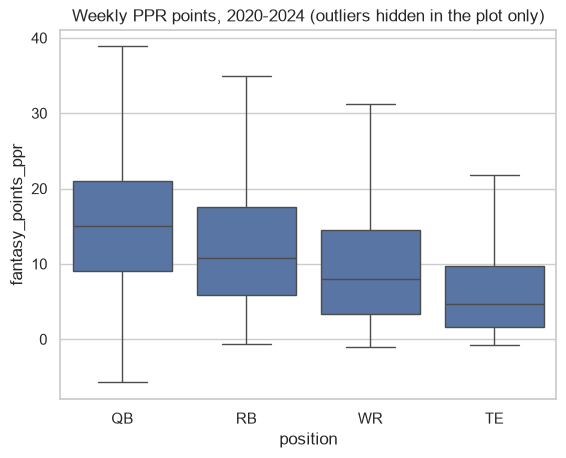

In [12]:
explore_rows = player_weeks[player_weeks["season"].isin(TRAIN_SEASONS)].copy()
points_by_position = explore_rows.groupby("position")[TARGET].agg(["count", "mean", "median", "std"]).reindex(POSITIONS)
print(f"{len(explore_rows):,} player-weeks, {TRAIN_SEASONS[0]}-{TRAIN_SEASONS[-1]}")
display(points_by_position.round(2))

sns.boxplot(data=explore_rows, x="position", y=TARGET, order=POSITIONS, showfliers=False)
plt.title("Weekly PPR points, 2020-2024 (outliers hidden in the plot only)")
plt.show()

**What we see:**
- 18,402 player-weeks. Mean points run from 6.46 (TE) to 15.18 (QB), so position sets the typical score.
- The median is below the mean at every position (WR 8.00 vs. 9.75, TE 4.70 vs. 6.46). Scores are skewed: a few big games pull the mean up.
- The spread is large next to the mean (standard deviation 6.45 to 8.80), so weekly points are noisy.

### 4.2 Stability and memory
How much does the past say about this week? We correlate this week's points with the player's points 1 to 8 games back and
with their average in the season before. Lags count games played, so they cross byes and season boundaries, and they reach
into the 2019 warm-up season. The second table is usage stability: last game's snap share, targets, and carries against this week's.

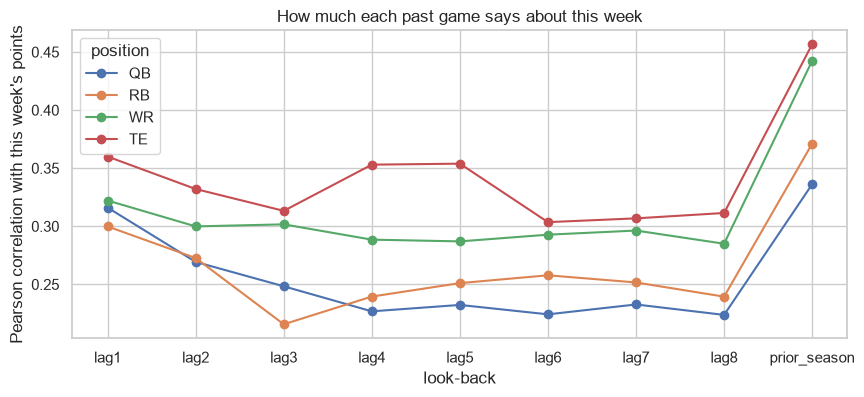

position,QB,RB,WR,TE
correlation with this week's points,,,,
lag1,0.316,0.300,0.322,0.360
lag2,0.269,0.273,0.300,0.332
lag3,0.248,0.216,0.302,0.313
lag4,0.227,0.239,0.288,0.353
lag5,0.232,0.251,0.287,0.354
lag6,0.224,0.258,0.293,0.304
lag7,0.233,0.252,0.296,0.307
lag8,0.224,0.239,0.285,0.311
prior_season,0.336,0.371,0.442,0.457


position,QB,RB,WR,TE
player-weeks with that look-back,,,,
lag1,2829,3293,8123,4157
lag2,2801,3278,8043,4133
lag3,2761,3261,7967,4110
lag4,2710,3242,7887,4088
lag5,2659,3218,7802,4062
lag6,2607,3190,7712,4036
lag7,2557,3157,7615,4006
lag8,2511,3122,7521,3970
prior_season,2503,2935,6974,3780


,offense_pct,targets,carries
last game vs. this game,,,
QB,0.411,0.554,0.492
RB,0.475,0.268,0.477
WR,0.554,0.398,0.423
TE,0.615,0.443,0.680


In [13]:
POINT_LAGS = [f"lag{i}" for i in range(1, 9)]              # points 1 to 8 games back
MEMORY_COLUMNS = POINT_LAGS + ["prior_season"]
STABILITY_STATS = ["offense_pct", "targets", "carries"]


def add_past_games(games):
    "Each player's points 1 to 8 games back and their usage in the game before."
    history = games.sort_values(KEY).copy()
    for lag, column in enumerate(POINT_LAGS, start=1):
        history[column] = history.groupby("gsis_id")[TARGET].shift(lag)
    for stat in STABILITY_STATS:
        history[f"{stat}_prior"] = history.groupby("gsis_id")[stat].shift(1)
    return history


def prior_season_mean(games):
    "Each player's mean points in the season before."
    prior = games.groupby(["gsis_id", "season"])[TARGET].mean().rename("prior_season").reset_index()
    return prior.assign(season=prior["season"] + 1)


def memory_table(rows, value):
    "One row per look-back, one column per position."
    return rows.pivot(index="history", columns="position", values=value).loc[MEMORY_COLUMNS, POSITIONS]


clean_games = player_games[(player_games["season"] < TEST_SEASON) & ~player_games["data_error"]]
history = add_past_games(clean_games)
prior_columns = [f"{stat}_prior" for stat in STABILITY_STATS]
memory_rows = (explore_rows[KEY + ["position", TARGET]]
               .merge(history[KEY + POINT_LAGS + STABILITY_STATS + prior_columns], on=KEY, validate="one_to_one")
               .merge(prior_season_mean(history), on=["gsis_id", "season"], how="left"))

memory = pd.DataFrame([
    {"position": position, "history": column, "n": len(part.dropna(subset=[column, TARGET])),
     "correlation": part[column].corr(part[TARGET])}
    for position, part in memory_rows.groupby("position") for column in MEMORY_COLUMNS])
stability = pd.DataFrame({stat: memory_rows.groupby("position").apply(lambda part: part[stat].corr(part[f"{stat}_prior"]))
                          for stat in STABILITY_STATS}).reindex(POSITIONS)

memory_table(memory, "correlation").plot(marker="o", figsize=(10, 4), xlabel="look-back",
                                         ylabel="Pearson correlation with this week's points",
                                         title="How much each past game says about this week")
plt.show()
display(memory_table(memory, "correlation").round(3).rename_axis("correlation with this week's points"),
        memory_table(memory, "n").rename_axis("player-weeks with that look-back"),
        stability.round(3).rename_axis("last game vs. this game"))

**What we see:**
- **One past game says little.** Last game's points correlate 0.300 to 0.360 with this week's, depending on position.
- **The fade is slow.** A game 8 games back still correlates 0.224 (QB) to 0.311 (TE), not far below last game. Older games carry almost as much as recent ones, which fits the long half-life (8 games) that CV picks in 5.7.
- **An average beats any single game.** Last season's mean correlates 0.336 to 0.457, above every single game at every position. So the features in section 5 are rolling averages, not single games.
- **Usage is steadier than points.** Last game's snap share correlates 0.411 (QB) to 0.615 (TE) with this game's, above the point correlations at every position. That is why usage gets its own feature family.
- These correlations describe memory. The half-life itself is chosen by CV in 5.7.

### 4.3 Early weeks and season drift
Two questions for later choices: do the first weeks of a season score differently, and do older seasons look different from
recent ones? Both are compared within position, so a change in the player mix does not drive the result.

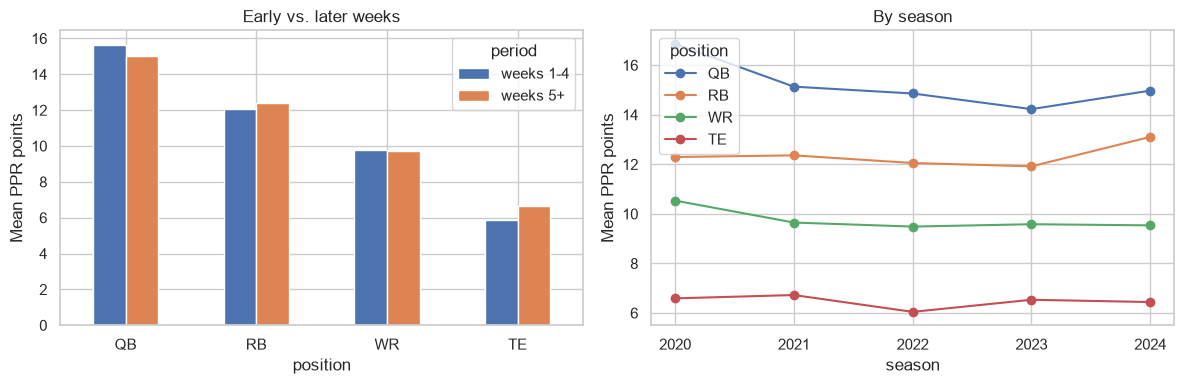

count   mean   std
position period                       
QB       weeks 1-4    658  15.66  8.76
         weeks 5+    2171  15.04  8.81
RB       weeks 1-4    796  12.07  8.64
         weeks 5+    2497  12.42  8.48
TE       weeks 1-4   1025   5.88  6.14
         weeks 5+    3132   6.65  6.54
WR       weeks 1-4   1945   9.78  8.33
         weeks 5+    6178   9.74  8.22

position,QB,RB,WR,TE
season,,,,
2020,16.86,12.29,10.54,6.59
2021,15.13,12.36,9.65,6.72
2022,14.86,12.05,9.49,6.05
2023,14.23,11.92,9.58,6.53
2024,14.97,13.11,9.54,6.44


position,QB,RB,WR,TE
early minus later,0.62,-0.35,0.05,-0.77


In [14]:
EARLY, LATER = f"weeks 1-{EARLY_SEASON_WEEKS}", f"weeks {EARLY_SEASON_WEEKS + 1}+"
explore_rows["period"] = np.where(explore_rows["week"] <= EARLY_SEASON_WEEKS, EARLY, LATER)
points_by_period = explore_rows.groupby(["position", "period"])[TARGET].agg(["count", "mean", "std"])
points_by_season = explore_rows.groupby(["season", "position"])[TARGET].agg(["count", "mean", "std"])
period_means = points_by_period["mean"].unstack().reindex(POSITIONS)
season_means = points_by_season["mean"].unstack()[POSITIONS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
period_means.plot.bar(ax=axes[0], ylabel="Mean PPR points", rot=0, title="Early vs. later weeks")
season_means.plot(marker="o", ax=axes[1], ylabel="Mean PPR points", title="By season")
axes[1].set_xticks(season_means.index)
plt.tight_layout()
plt.show()
display(points_by_period.round(2), season_means.round(2),
        (period_means[EARLY] - period_means[LATER]).round(2).rename("early minus later").to_frame().T)

**What we see:**
- **Early vs. later:** the early-minus-later gap runs from -0.77 points (TE, 5.88 vs. 6.65) to +0.62 (QB, 15.66 vs. 15.04). RB is 0.35 lower early and WR is level (9.78 vs. 9.74). These gaps are small next to a weekly spread of 6 to 9 points.
- **By season:** 2020 was the highest-scoring season for QB (16.86) and WR (10.54). Since 2021, QB has stayed between 14.23 and 15.13 and WR between 9.49 and 9.65. RB (11.92 to 13.11) and TE (6.05 to 6.72) show no trend.
- So older seasons look much like recent ones. Whether they should count less in training is a question for time-ordered CV, which section 6.4 answers.

### 4.4 Vegas lines and production
Lines are set before the game, so they are pre-game information. A team's implied points are half the game total plus half
the points the team is favored by. Correlations are within position.

,total_line,team_favored_by,implied_team_points
correlation with points,,,
QB,0.244,0.208,0.313
RB,0.070,0.076,0.103
WR,0.112,0.087,0.136
TE,0.076,0.111,0.136


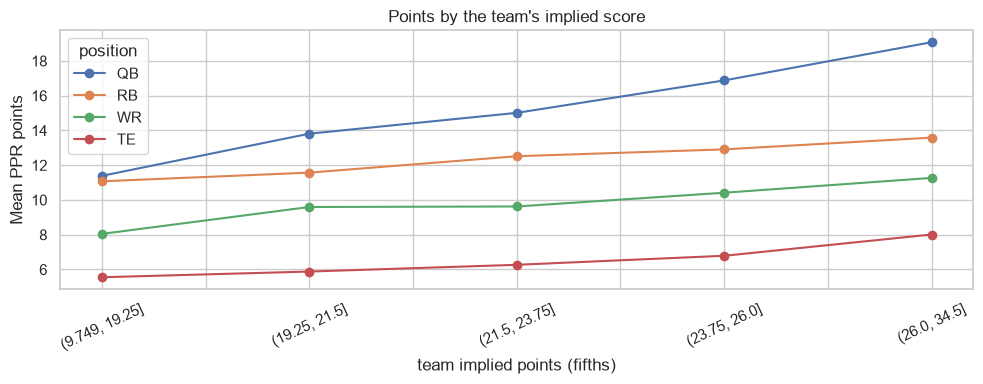

In [15]:
VEGAS_COLUMNS = ["total_line", "team_favored_by", "implied_team_points"]
explore_rows["implied_team_points"] = (explore_rows["total_line"] + explore_rows["team_favored_by"]) / 2
vegas = pd.DataFrame({column: explore_rows.groupby("position").apply(lambda part: part[column].corr(part[TARGET]))
                      for column in VEGAS_COLUMNS}).reindex(POSITIONS)
display(vegas.round(3).rename_axis("correlation with points"))

explore_rows["implied_bin"] = pd.qcut(explore_rows["implied_team_points"], 5, duplicates="drop")
points_by_implied = explore_rows.groupby(["implied_bin", "position"], observed=True)[TARGET].mean().unstack()[POSITIONS]
points_by_implied.plot(marker="o", figsize=(10, 4), xlabel="team implied points (fifths)", ylabel="Mean PPR points",
                       title="Points by the team's implied score")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**What we see:**
- Implied team points track QB scoring best (correlation 0.313). For the other positions the link is weak: 0.103 for RB and 0.136 for WR and TE.
- Implied points beat the total alone (QB 0.244) and the spread alone (QB 0.208), so we use all three as the game-script family in 5.3.
- The lines describe the team. How a team's points are split among its players still depends on usage.

### 4.5 How good are the experts?
This is the bar for section 9. We keep training-season player-weeks that have an expert rank made before kickoff, and re-rank
within each position-week so both sides cover the same players. The metrics are the two ranking scores used in the rest of
the notebook (defined in 5.6): Spearman within a position-week, and the share of the experts' top 12 who finished top 12.

13,839 matched player-weeks in 74 weeks. Experts' mean weekly Spearman 0.509, top-12 hit rate 0.519


,spearman,top12_hit_rate
position,,
QB,0.440,0.605
RB,0.466,0.553
WR,0.549,0.368
TE,0.581,0.548


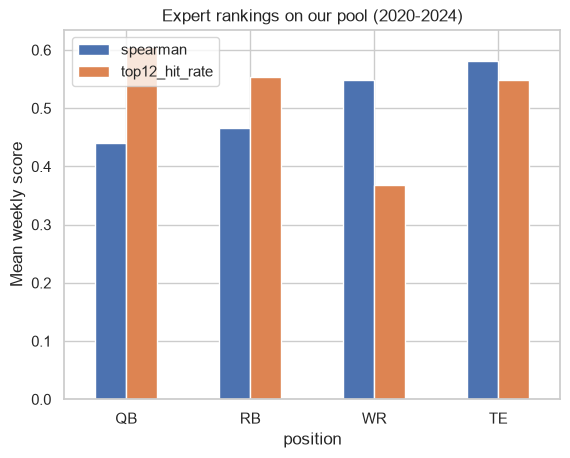

In [16]:
def expert_week_scores(week):
    "The experts' ranking scores in one position-week."
    actual_rank, expert_rank = week[TARGET].rank(ascending=False), week["ecr_pos_rank"].rank()
    expert_top = set(week.nsmallest(TOP_N, "ecr_pos_rank").index)
    actual_top = set(week.nlargest(TOP_N, TARGET).index)
    return pd.Series({"spearman": expert_rank.corr(actual_rank, method="spearman"),
                      "top12_hit_rate": len(expert_top & actual_top) / TOP_N})


pre_game_ecr = ecr_weekly.loc[~ecr_weekly["played_before_snapshot"], KEY + ["ecr_pos_rank"]]
expert_rows = explore_rows.merge(pre_game_ecr, on=KEY, validate="one_to_one")
expert_weekly = expert_rows.groupby(["season", "week", "position"]).apply(expert_week_scores)
expert_by_position = expert_weekly.groupby("position").mean().reindex(POSITIONS)

print(f"{len(expert_rows):,} matched player-weeks in {len(expert_rows[['season', 'week']].drop_duplicates())} weeks. "
      f"Experts' mean weekly Spearman {expert_weekly['spearman'].mean():.3f}, "
      f"top-12 hit rate {expert_weekly['top12_hit_rate'].mean():.3f}")
display(expert_by_position.round(3))
expert_by_position.plot.bar(rot=0, ylabel="Mean weekly score", title="Expert rankings on our pool (2020-2024)")
plt.show()

**What we see:**
- On 13,839 matched player-weeks in 74 weeks, the experts' mean weekly Spearman is 0.509 and their top-12 hit rate is 0.519. That is the bar: even the experts explain only part of the weekly order.
- Their ranking is best for TE (0.581) and WR (0.549) and weakest for QB (0.440) and RB (0.466).
- The WR hit rate is the lowest (0.368) because the WR pool is the largest, so 12 spots are the hardest to fill.
- Weeks with no snapshot and games played before the snapshot are left out, as in section 3.6.

## 5. Features

Goal: pre-game features for every player-week, grouped into families. Every rolling feature for week *t* uses only
games before week *t*. Steps:
1. Per-game stats to roll (points, usage shares, luck).
2. Rolling windows: last game, last 3, recency-weighted average, season to date.
3. Game script (Vegas), opponent strength, and the player's current situation (team change, injuries around them).
4. Shared evaluation code (CV folds and metrics) that every modeling section uses.
5. Pick the recency half-life, then measure what each feature family adds.

### 5.1 Per-game stats
These are the raw numbers from each played game that the rolling windows summarize. Shares are the player's part of
the team total in that game. Luck is points minus expected points: positive means the player scored more than
their opportunities usually produce.

In [17]:
def add_game_stats(games):
    g = games.sort_values(["gsis_id", "season", "week"]).reset_index(drop=True)
    g["points"] = g[TARGET]
    g["snap_share"] = g["offense_pct"].fillna(0)
    g["target_share"] = g["target_share"].fillna(0)
    g["air_yards_share"] = g["air_yards_share"].fillna(0)
    g["opportunities"] = g["attempts"].fillna(0) + g["carries"].fillna(0) + g["targets"].fillna(0)
    team_carries = g.groupby(["season", "week", "team"])["carries"].transform("sum")
    g["carry_share"] = (g["carries"].fillna(0) / team_carries.replace(0, np.nan)).fillna(0)
    g["points_over_expected"] = g["points"] - g["expected_points"]
    return g


games = add_game_stats(pd.read_parquet(PROCESSED_DIR / "player_games.parquet"))
player_weeks = pd.read_parquet(PROCESSED_DIR / "player_weeks.parquet")
injuries = load_cached("injuries", lambda: nfl.load_injuries(ALL_SEASONS))

PRODUCTION_STATS = ["points", "expected_points"]
USAGE_STATS = ["snap_share", "target_share", "carry_share", "air_yards_share", "opportunities"]
games[["gsis_id", "season", "week", "team"] + PRODUCTION_STATS + USAGE_STATS + ["points_over_expected"]].head()

,gsis_id,season,week,team,points,expected_points,snap_share,target_share,carry_share,air_yards_share,opportunities,points_over_expected
0,00-0019596,2019,1,NE,25.64,17.84,1.00,0.0,0.000000,0.0,36.0,7.80
1,00-0019596,2019,2,NE,24.66,22.49,1.00,0.0,0.057143,0.0,30.0,2.17
2,00-0019596,2019,3,NE,20.14,20.87,0.95,0.0,0.074074,0.0,44.0,-0.73
3,00-0019596,2019,4,NE,3.70,13.97,1.00,0.0,0.130435,0.0,42.0,-10.27
4,00-0019596,2019,5,NE,23.92,23.87,0.92,0.0,0.000000,0.0,42.0,0.05


**What we see:** one row per played game (46,945 from 2019 to 2025) with the stats we roll forward. Tom Brady's 2019 week 4 shows why luck matters: 3.7 points on 13.97 expected points (-10.27 luck).

### 5.2 Rolling windows over past games
For each stat we keep four views of the past, each from games before this one only:
- `last1`: the last game played
- `last3`: the mean of the last 3 games
- `recent`: a recency-weighted mean of all past games, where a game's weight halves every `half_life` games
  (with `half_life=None` it is a plain equal-weight mean of the last 8 games, the version recency has to beat)
- `season`: the mean of earlier games this season (in week 1 it falls back to `recent`)

The `recent` window runs across seasons, so early-season weeks still have history.

In [18]:
def weighted_mean(past_values, half_life):
    if half_life is None:
        return past_values.rolling(PLAIN_WINDOW_GAMES, min_periods=1).mean()
    return past_values.ewm(halflife=half_life, min_periods=1).mean()


def past_windows(g, stat, half_life):
    """Four summaries of a player's games before each row."""
    past = g.groupby("gsis_id")[stat].shift(1)          # shift(1): this game is never included
    by_player = past.groupby(g["gsis_id"])
    out = pd.DataFrame(index=g.index)
    out[f"{stat}_last1"] = past
    out[f"{stat}_last3"] = by_player.transform(lambda s: s.rolling(3, min_periods=1).mean())
    out[f"{stat}_recent"] = by_player.transform(lambda s: weighted_mean(s, half_life))
    season_past = g.groupby(["gsis_id", "season"])[stat].transform(lambda s: s.shift(1).expanding().mean())
    out[f"{stat}_season"] = season_past.fillna(out[f"{stat}_recent"])
    return out


def luck_windows(g):
    """Luck evens out, so it gets a long memory and a season-to-date mean."""
    past = g.groupby("gsis_id")["points_over_expected"].shift(1)
    return pd.DataFrame({
        "luck_recent": past.groupby(g["gsis_id"]).transform(
            lambda s: s.ewm(halflife=LUCK_HALF_LIFE_GAMES, min_periods=1).mean()),
        "luck_season": g.groupby(["gsis_id", "season"])["points_over_expected"]
                        .transform(lambda s: s.shift(1).expanding().mean()).fillna(0),
    }, index=g.index)

### 5.3 Game script and opponent strength
- **Game script** comes from the Vegas lines for this game: the team's implied points
  (half the total plus half the spread), how much the team is favored by, the total, and home or away.
- **Opponent strength** is the PPR points the opponent allowed to this position in its earlier games,
  recency-weighted the same way as the player's stats.

In [19]:
def game_script_features(g):
    return pd.DataFrame({
        "implied_team_points": g["total_line"] / 2 + g["team_favored_by"] / 2,
        "favored_by": g["team_favored_by"],
        "game_total": g["total_line"],
        "is_home": g["is_home"],
    }, index=g.index)


def opponent_features(g, half_life):
    allowed = (g.groupby(["opponent", "position", "season", "week"])["points"].sum()
               .reset_index().sort_values(["season", "week"]))
    past = allowed.groupby(["opponent", "position"])["points"].shift(1)
    allowed["opp_points_allowed"] = past.groupby([allowed["opponent"], allowed["position"]]).transform(
        lambda s: weighted_mean(s, half_life))
    keys = ["opponent", "position", "season", "week"]
    merged = g[keys].merge(allowed[keys + ["opp_points_allowed"]], on=keys, how="left")
    return merged[["opp_points_allowed"]].set_index(g.index)

### 5.4 Current situation
Features that say whether the past still describes the present:
- `games_this_season`, `weeks_since_last_game` (large after an injury), `changed_team` since the last game
- `last_season_ppg`, with `no_last_season` for players without one
- from the pre-game injury report: the player is `questionable`, the team's starting QB is out or doubtful,
  and the target and carry share that teammates listed out or doubtful usually take (`vacated_*_share`)

In [20]:
def history_features(g):
    order = g[["season", "week"]].drop_duplicates().sort_values(["season", "week"])
    week_index = order.assign(week_index=range(len(order)))
    idx = g[["season", "week"]].merge(week_index, on=["season", "week"], how="left")["week_index"].to_numpy()
    prev_team = g.groupby("gsis_id")["team"].shift(1)
    ppg = g.groupby(["gsis_id", "season"])["points"].mean().rename("last_season_ppg").reset_index()
    ppg["season"] += 1
    last_season = g[["gsis_id", "season"]].merge(ppg, on=["gsis_id", "season"], how="left")["last_season_ppg"]
    return pd.DataFrame({
        "games_this_season": g.groupby(["gsis_id", "season"]).cumcount(),
        "weeks_since_last_game": idx - pd.Series(idx, index=g.index).groupby(g["gsis_id"]).shift(1),
        "changed_team": (prev_team.notna() & (prev_team != g["team"])).astype(int),
        "last_season_ppg": last_season.fillna(0).to_numpy(),
        "no_last_season": last_season.isna().astype(int).to_numpy(),
    }, index=g.index)


def clean_injury_report(injuries):
    inj = regular_season(injuries, "game_type").dropna(subset=["gsis_id"]).copy()
    inj = inj.astype({"season": int, "week": int}).assign(team=lambda d: fix_team(d["team"]))
    inj = inj.sort_values("date_modified").drop_duplicates(["gsis_id", "season", "week"], keep="last")
    inj["out_or_doubtful"] = inj["report_status"].isin(["Out", "Doubtful"])
    return inj[["gsis_id", "season", "week", "team", "report_status", "out_or_doubtful"]]


def usage_before_week(g, keys, half_life):
    """Each player's recency-weighted usage through their last game before the given (season, week)."""
    hist = g[["gsis_id", "season", "week", "position", "snap_share", "target_share", "carry_share"]].copy()
    for stat in ["snap_share", "target_share", "carry_share"]:
        hist[stat] = hist.groupby("gsis_id")[stat].transform(lambda s: weighted_mean(s, half_life))
    hist["order"] = (hist["season"] * 100 + hist["week"]).astype("int64")
    keys = keys.assign(order=(keys["season"] * 100 + keys["week"]).astype("int64")).sort_values("order")
    return pd.merge_asof(keys, hist.drop(columns=["season", "week"]).sort_values("order"),
                         on="order", by="gsis_id", allow_exact_matches=False)


def injury_features(g, injury_report, half_life):
    key = ["gsis_id", "season", "week"]
    listed = usage_before_week(g, injury_report[injury_report["out_or_doubtful"]], half_life)
    team_week = ["season", "week", "team"]
    vacated = listed.groupby(team_week)[["target_share", "carry_share"]].sum().add_prefix("vacated_")
    qb_out = (listed[(listed["position"] == "QB") & (listed["snap_share"] >= 0.5)]
              .groupby(team_week).size().gt(0).rename("starting_qb_out"))
    out = g[key + ["team"]].merge(vacated.reset_index(), on=team_week, how="left")
    out = out.merge(qb_out.reset_index(), on=team_week, how="left")
    status = injury_report[key + ["report_status"]]
    out = out.merge(status, on=key, how="left")
    return pd.DataFrame({
        "questionable": out["report_status"].eq("Questionable").astype(int).to_numpy(),
        "starting_qb_out": out["starting_qb_out"].fillna(False).astype(int).to_numpy(),
        "vacated_target_share": out["vacated_target_share"].fillna(0).to_numpy(),
        "vacated_carry_share": out["vacated_carry_share"].fillna(0).to_numpy(),
    }, index=g.index)


injury_report = clean_injury_report(injuries)
print(f"Injury report rows: {len(injury_report):,};  listed out or doubtful: {injury_report['out_or_doubtful'].mean():.1%}")

Injury report rows: 38,599;  listed out or doubtful: 21.6%


**What we see:** 38,599 injury-report rows from 2019 to 2025, 21.6% of them listed out or doubtful. The report is published before each game, so it is pre-game information.

### 5.5 Build the feature table
All families are computed on every played game (so the history is complete), then cut down to the modeling rows.

In [21]:
def build_features(games, half_life):
    g = games
    parts = [past_windows(g, stat, half_life) for stat in PRODUCTION_STATS + USAGE_STATS]
    parts += [luck_windows(g), game_script_features(g), opponent_features(g, half_life),
              history_features(g), injury_features(g, injury_report, half_life),
              pd.get_dummies(g["position"], prefix="pos", dtype=int)]
    table = pd.concat([g[["gsis_id", "season", "week", "position", "team", "kickoff", TARGET]]] + parts, axis=1)
    return table.merge(player_weeks[["gsis_id", "season", "week"]], on=["gsis_id", "season", "week"])


def window_columns(stats):
    return [f"{s}_{w}" for s in stats for w in ["last1", "last3", "recent", "season"]]


FEATURE_FAMILIES = {
    "position": [f"pos_{p}" for p in POSITIONS],
    "recent_production": window_columns(PRODUCTION_STATS),
    "usage": window_columns(USAGE_STATS),
    "luck": ["luck_recent", "luck_season"],
    "game_script": ["implied_team_points", "favored_by", "game_total", "is_home"],
    "opponent": ["opp_points_allowed"],
    "situation": ["games_this_season", "weeks_since_last_game", "changed_team", "last_season_ppg", "no_last_season",
                  "questionable", "starting_qb_out", "vacated_target_share", "vacated_carry_share"],
}
ALL_FEATURES = [c for cols in FEATURE_FAMILIES.values() for c in cols]

features_by_half_life = {hl: build_features(games, hl) for hl in HALF_LIFE_CANDIDATES + [None]}
example = features_by_half_life[HALF_LIFE_CANDIDATES[0]]
print(f"{len(example):,} rows x {len(ALL_FEATURES)} features in {len(FEATURE_FAMILIES)} families")
assert example[ALL_FEATURES].notna().all().all(), "missing feature values"

22,145 rows x 48 features in 7 families


**What we see:** 22,145 rows and 48 features in 7 families, with no missing values.
- Every pool player has at least one earlier game, so the windows always have history.
- Players with no prior season get `last_season_ppg = 0` and `no_last_season = 1` (12.0% of training rows).

**Do the situation features point the right way?** Mean PPR points in training seasons, with and without each flag.

In [22]:
train_example = example[example["season"].isin(TRAIN_SEASONS)]
display(pd.concat({flag: train_example.groupby(["position", flag])[TARGET].mean().unstack()
                   for flag in ["changed_team", "questionable", "starting_qb_out"]}, axis=1).round(2))

changed_team       questionable        starting_qb_out       
changed_team            0     1            0      1               0      1
position                                                                  
QB                  15.45  7.47        15.24  13.00           15.40  10.99
RB                  12.44  7.15        12.38  11.74           12.43  10.76
TE                   6.51  3.96         6.49   5.83            6.50   5.91
WR                   9.85  5.15         9.79   9.16            9.86   8.05

**What we see:** every flag lowers scoring, as expected.
- A player in their first game for a new team scores far less (WR 9.85 vs. 5.15 points), so old usage overstates them.
- A WR whose starting QB is out drops from 9.86 to 8.05, and a questionable tag costs about half a point to 2 points.
- Changed team (2.2% of rows), questionable (5.6%), and QB out (5.9%) are rare, so they matter for a few players a week, not the average.

### 5.6 Shared evaluation: time-ordered CV and metrics
Every modeling section uses these two functions, so all results are comparable.
- `cv_folds`: expanding window. To validate on season *s*, train on every season from 2020 to *s*-1. 2025 is never used.
- `evaluate`: point error (RMSE, MAE) and ranking quality within each position-week: Spearman rank correlation and the
  share of our top 12 who actually finished top 12.

In [23]:
def cv_folds(data):
    for season in CV_VALID_SEASONS:
        train = data.index[data["season"].between(TRAIN_SEASONS[0], season - 1)]
        valid = data.index[data["season"] == season]
        yield season, train, valid


def top_n_hit_rate(week):
    predicted_top = set(week.nlargest(TOP_N, "pred").index)
    actual_top = set(week.nlargest(TOP_N, TARGET).index)
    return len(predicted_top & actual_top) / TOP_N


def evaluate(data, pred):
    d = data.assign(pred=np.asarray(pred))
    groups = d.groupby(["season", "week", "position"])
    return {
        "rmse": float(np.sqrt(((d["pred"] - d[TARGET]) ** 2).mean())),
        "mae": float((d["pred"] - d[TARGET]).abs().mean()),
        "spearman": float(groups.apply(lambda w: w["pred"].corr(w[TARGET], method="spearman")).mean()),
        "top12_hit_rate": float(groups.apply(top_n_hit_rate).mean()),
    }


def cross_validate(model, data, columns):
    """Fit on each expanding-window fold; return mean metrics and the out-of-fold predictions."""
    from sklearn.base import clone
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        fitted = clone(model).fit(data.loc[train, columns], data.loc[train, TARGET])
        preds.loc[valid] = fitted.predict(data.loc[valid, columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds

### 5.7 How much should recent games count?
The same Ridge model, using production and usage features, built four ways: equal weight over the last 8 games, and
recency-weighted with a half-life of 3, 5, 8, 12, or 16 games. We keep the half-life with the best CV rank correlation.

In [24]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
recency_columns = FEATURE_FAMILIES["position"] + FEATURE_FAMILIES["recent_production"] + FEATURE_FAMILIES["usage"]


def label(half_life):
    return f"equal weight, last {PLAIN_WINDOW_GAMES}" if half_life is None else f"half-life {half_life} games"


def train_rows(table):
    return table[table["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)


recency_results = pd.DataFrame({
    label(hl): cross_validate(ridge, train_rows(table), recency_columns)[0]
    for hl, table in features_by_half_life.items()
}).T.round(4)
display(recency_results)

HALF_LIFE = max(HALF_LIFE_CANDIDATES, key=lambda hl: recency_results.loc[label(hl), "spearman"])
features = features_by_half_life[HALF_LIFE]
print(f"Chosen half-life: {HALF_LIFE} games")

,rmse,mae,spearman,top12_hit_rate
half-life 3 games,6.8969,5.2975,0.4959,0.4784
half-life 5 games,6.8791,5.2846,0.4999,0.4819
half-life 8 games,6.8725,5.2824,0.5014,0.4826
half-life 12 games,6.8730,5.2867,0.5013,0.4857
half-life 16 games,6.8753,5.2909,0.5012,0.4861
"equal weight, last 8",6.9207,5.3153,0.4901,0.4765


Chosen half-life: 8 games


**What we see:**
- Recency weighting beats equal weighting at every half-life. The equal-weight last-8 mean has the worst rank correlation (0.490) and RMSE (6.92).
- A half-life of 8 games is best (Spearman 0.501, RMSE 6.87), and 12 and 16 are within 0.0002 of it.
- So recent games should count more, but the weight should fade slowly: a game 8 games back still counts half as much as last week's.

### 5.8 What each feature family adds
Families are added one at a time to Ridge and a random forest (both untuned here; tuning is in section 6).
Two no-model baselines show the floor: last game's points and the mean of the last 3 games.

rmse     mae  spearman  top12_hit_rate
no model      baseline: last game     9.0658  6.7694    0.3532          0.4059
              baseline: last 3 games  7.5943  5.7843    0.4234          0.4456
Ridge         + recent_production     6.9118  5.3199    0.4917          0.4792
              + usage                 6.8725  5.2824    0.5014          0.4826
              + luck                  6.8715  5.2828    0.5016          0.4826
              + game_script           6.8490  5.2345    0.5071          0.4915
              + opponent              6.8464  5.2205    0.5086          0.4938
              + situation             6.8090  5.1939    0.5146          0.4896
Random forest + recent_production     6.9364  5.3250    0.4855          0.4792
              + usage                 6.8929  5.3067    0.4956          0.4823
              + luck                  6.8888  5.3093    0.4964          0.4807
              + game_script           6.8415  5.2598    0.5081          0.4896
              + opponent              6.8374  5.2563    0.5079          0.4873
              + situation             6.8092  5.2360    0.5140          0.4888

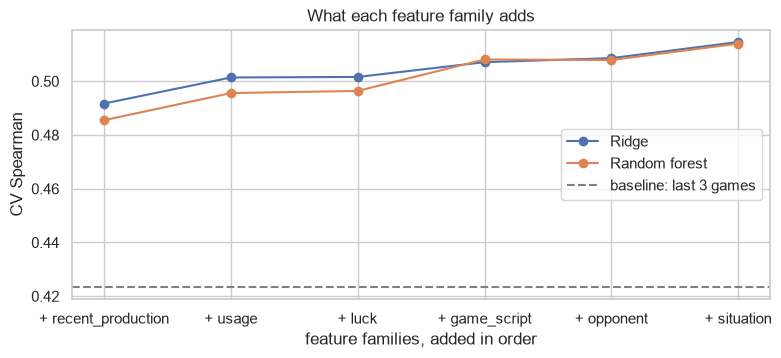

In [25]:
from sklearn.ensemble import RandomForestRegressor

train_features = train_rows(features)
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED)


def baseline_scores(data):
    scored = data[data["season"].isin(CV_VALID_SEASONS)]
    return {"baseline: last game": evaluate(scored, scored["points_last1"]),
            "baseline: last 3 games": evaluate(scored, scored["points_last3"])}


def family_ladder(data, model):
    results, columns = {}, []
    for family, cols in FEATURE_FAMILIES.items():
        columns = columns + cols
        if family != "position":
            results[f"+ {family}"] = cross_validate(model, data, columns)[0]
    return results


family_results = pd.concat({
    "no model": pd.DataFrame(baseline_scores(train_features)).T,
    "Ridge": pd.DataFrame(family_ladder(train_features, ridge)).T,
    "Random forest": pd.DataFrame(family_ladder(train_features, forest)).T,
}).round(4)
display(family_results)

ladder = family_results.loc[["Ridge", "Random forest"], "spearman"].unstack(0)
ladder = ladder.loc[[f"+ {family}" for family in FEATURE_FAMILIES if family != "position"]]
ax = ladder.plot(marker="o", figsize=(9, 3.5), xlabel="feature families, added in order", ylabel="CV Spearman",
                 title="What each feature family adds")
ax.axhline(family_results.loc[("no model", "baseline: last 3 games"), "spearman"], color="gray", linestyle="--",
           label="baseline: last 3 games")
ax.legend()
plt.show()

**What we see:**
- Both models beat the no-model baselines by a wide margin: RMSE 6.81 vs. 7.59 for the last-3 average, and rank correlation 0.515 vs. 0.423.
- **Biggest gains:** usage (+0.010 Spearman for Ridge), the situation family (+0.006 Spearman, -0.037 RMSE, the largest RMSE drop after the first family), and game script (+0.006).
- **Luck adds almost nothing** (+0.0002). Expected points already carries most of that signal. We keep it for now and let the regularized models in section 6 decide.
- Ridge and the untuned random forest end level (Spearman 0.515 vs. 0.514), so model choice is open for section 6.

### 5.9 Leakage checks and a spot check
- **Leakage test:** for 300 random rows, recompute three features by hand from only the games before that week and
  compare to the table.
- **ECR check:** no ECR column is in the features.
- **Spot check:** Christian McCaffrey, traded from CAR to SF in 2022 week 7, and back from injured reserve in 2024 week 10.

In [26]:
def recompute_by_hand(row):
    past = games[(games["gsis_id"] == row["gsis_id"]) &
                 ((games["season"] < row["season"]) | ((games["season"] == row["season"]) & (games["week"] < row["week"])))]
    return pd.Series({"points_last1": past["points"].iloc[-1],
                      "points_last3": past["points"].tail(3).mean(),
                      "games_this_season": (past["season"] == row["season"]).sum()})


sample = features.sample(300, random_state=SEED)
by_hand = sample.apply(recompute_by_hand, axis=1)
mismatches = (by_hand - sample[by_hand.columns]).abs().gt(1e-9).sum()
print("Leakage test mismatches per feature:", mismatches.to_dict())
assert mismatches.sum() == 0
assert not [c for c in ALL_FEATURES if "ecr" in c.lower()], "ECR column in features"
assert not features.duplicated(["gsis_id", "season", "week"]).any()

cmc = features[(features["gsis_id"] == "00-0033280") &
               (((features["season"] == 2022) & features["week"].between(5, 9)) |
                ((features["season"] == 2024) & features["week"].between(10, 12)))]
display(cmc[["season", "week", "team", "changed_team", "weeks_since_last_game", "games_this_season",
             "points_last1", "points_recent", "snap_share_last3", TARGET]])

Leakage test mismatches per feature: {'points_last1': 0, 'points_last3': 0, 'games_this_season': 0}


,season,week,team,changed_team,weeks_since_last_game,games_this_season,points_last1,points_recent,snap_share_last3,fantasy_points_ppr
5529,2022,5,CAR,0,1.0,4.0,25.8,21.790617,0.860000,23.40
5530,2022,6,CAR,0,1.0,5.0,23.4,21.933959,0.843333,22.80
5531,2022,7,SF,1,1.0,6.0,22.8,22.010628,0.863333,8.20
5532,2022,8,SF,0,1.0,7.0,8.2,20.794715,0.670000,40.26
5558,2024,10,SF,0,11.0,0.0,13.1,23.600816,0.770000,16.70
5559,2024,11,SF,0,1.0,1.0,16.7,23.024895,0.806667,14.60
5560,2024,12,SF,0,1.0,2.0,14.6,22.322102,0.786667,7.80


**What we see:**
- The leakage test matches on all 300 rows.
- In McCaffrey's first SF game (2022 week 7), `changed_team` = 1. The return in 2024 week 10 shows `weeks_since_last_game` = 11 and `games_this_season` = 0.
- At that point McCaffrey's recency-weighted mean (23.6) is still built on the 2023 season, which is the carry-over across seasons working as intended.

In [27]:
features.to_parquet(PROCESSED_DIR / "features.parquet", index=False)
(PROCESSED_DIR / "feature_families.json").write_text(pd.Series(FEATURE_FAMILIES).to_json(indent=2))
print(f"Saved features {features.shape} with half-life {HALF_LIFE}")

Saved features (22145, 55) with half-life 8


## 6. Points regression (main task)

Goal: find the best model for weekly points. Every model is scored with the shared folds from 5.6 (validate on 2022, 2023, 2024; 2025 is not used).
- **Selection rule, set before looking at results:** pick on mean weekly Spearman within position, because the final comparison to the experts is about rankings. RMSE is reported next to it.
- **Steps:** the bar to beat (6.1), tune a range of course models (6.2), combine the best (6.3), tune how much the past counts (6.4), check overfitting (6.5), look at where the errors are (6.6), the comparison table (6.7), and the saved predictions (6.8).

### 6.1 The bar to beat
Two no-model baselines and the untuned Ridge from section 5.8.

In [28]:
bar_to_beat = pd.DataFrame({**baseline_scores(train_features),
                            "Ridge, untuned (5.8)": cross_validate(ridge, train_features, ALL_FEATURES)[0]}).T.round(4)
bar_to_beat

,rmse,mae,spearman,top12_hit_rate
baseline: last game,9.0658,6.7694,0.3532,0.4059
baseline: last 3 games,7.5943,5.7843,0.4234,0.4456
"Ridge, untuned (5.8)",6.8090,5.1939,0.5146,0.4896


**What we see:** the bar is the untuned Ridge: RMSE 6.81, Spearman 0.515, top-12 hit rate 0.490. The last-3 average is far behind (RMSE 7.59, Spearman 0.423), and last game alone is worst (RMSE 9.07, Spearman 0.353).

### 6.2 Tune a range of course models
Each model gets a small grid, and every setting is scored with the same folds. Models that use distances or penalties
(linear, KNN, SVM, MLP) are standardized first. The table keeps the best setting per model.

In [29]:
import itertools
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import (AdaBoostRegressor, BaggingRegressor, HistGradientBoostingRegressor,
                              StackingRegressor, VotingRegressor)
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor


warnings.filterwarnings("ignore", message="A worker stopped")  # joblib restarting a worker; results are unaffected


def scaled(*steps):
    return make_pipeline(StandardScaler(), *steps)


def options(**choices):
    "Every combination of the given settings, as a list of dicts."
    return [dict(zip(choices, combo)) for combo in itertools.product(*choices.values())]


def make_lasso(**params):
    return Lasso(max_iter=5000, **params)


def make_boosting(**params):
    return HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **params)


def make_mlp(**params):
    return MLPRegressor(early_stopping=True, max_iter=300, random_state=SEED, **params)


MODEL_GRIDS = {  # name: (how to build it, settings to try)
    "Linear regression": (lambda: scaled(LinearRegression()), [{}]),
    "Ridge": (lambda **p: scaled(Ridge(**p)), options(alpha=[1, 10, 100, 1000])),
    "Lasso": (lambda **p: scaled(make_lasso(**p)), options(alpha=[0.003, 0.01, 0.03, 0.1])),
    "Polynomial (degree 2) + Lasso": (
        lambda **p: scaled(PolynomialFeatures(2, include_bias=False), StandardScaler(), Lasso(max_iter=3000, **p)),
        options(alpha=[0.05, 0.1, 0.2])),
    "Decision tree": (lambda **p: DecisionTreeRegressor(min_samples_leaf=50, random_state=SEED, **p),
                      options(max_depth=[3, 5, 7, 10])),
    "KNN": (lambda **p: scaled(KNeighborsRegressor(**p)), options(n_neighbors=[25, 50, 100, 200])),
    "SVM (RBF kernel)": (lambda **p: scaled(SVR(epsilon=2, **p)), options(C=[0.3, 1, 3])),
    "MLP": (lambda **p: scaled(make_mlp(**p)), options(hidden_layer_sizes=[(32,), (64,), (64, 32)], alpha=[1, 10, 30, 100])),
    "Bagged trees": (
        lambda **p: BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=20), n_estimators=100, random_state=SEED, **p),
        options(max_samples=[0.5, 1.0])),
    "Random forest": (lambda **p: RandomForestRegressor(n_estimators=200, random_state=SEED, **p),
                      options(min_samples_leaf=[10, 20], max_features=[0.33, 0.5])),
    "AdaBoost": (lambda **p: AdaBoostRegressor(DecisionTreeRegressor(max_depth=5), learning_rate=0.01, random_state=SEED, **p),
                 options(n_estimators=[50, 100])),
    "Gradient boosting": (lambda **p: make_boosting(**p),
                          options(max_iter=[100, 300], learning_rate=[0.02, 0.05], max_leaf_nodes=[4, 8, 15],
                                  min_samples_leaf=[40])),
}


def score_setting(name, params):
    scores, _ = cross_validate(MODEL_GRIDS[name][0](**params), train_features, ALL_FEATURES)
    return {"model": name, "params": params, **scores}


def tune_all(grids):
    jobs = [(name, params) for name, (_, settings) in grids.items() for params in settings]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(score_setting)(name, params) for name, params in jobs))


tuning = tune_all(MODEL_GRIDS)
best_per_model = (tuning.loc[tuning.groupby("model")[SELECT_METRIC].idxmax()]
                  .sort_values(SELECT_METRIC, ascending=False).set_index("model"))
best_params = best_per_model["params"].to_dict()
print(f"{len(tuning)} settings tried across {len(MODEL_GRIDS)} models")

lasso_fit = MODEL_GRIDS["Lasso"][0](**best_params["Lasso"]).fit(train_features[ALL_FEATURES], train_features[TARGET])
dropped_by_lasso = [c for c, coef in zip(ALL_FEATURES, lasso_fit[-1].coef_) if coef == 0]
print(f"Lasso sets {len(dropped_by_lasso)} of {len(ALL_FEATURES)} coefficients to zero: {dropped_by_lasso}")
with pd.option_context("display.max_colwidth", None):
    display(best_per_model.round(4))

55 settings tried across 12 models
Lasso sets 14 of 48 coefficients to zero: ['pos_RB', 'expected_points_last1', 'expected_points_last3', 'target_share_last1', 'target_share_last3', 'air_yards_share_last3', 'air_yards_share_season', 'opportunities_last1', 'opportunities_last3', 'opportunities_recent', 'opportunities_season', 'luck_recent', 'luck_season', 'favored_by']


,params,rmse,mae,spearman,top12_hit_rate
model,,,,,
MLP,"{'hidden_layer_sizes': (64, 32), 'alpha': 30}",6.7801,5.1746,0.5227,0.4977
Polynomial (degree 2) + Lasso,{'alpha': 0.1},6.7937,5.2131,0.5190,0.4896
Gradient boosting,"{'max_iter': 300, 'learning_rate': 0.02, 'max_leaf_nodes': 8, 'min_samples_leaf': 40}",6.7919,5.2113,0.5189,0.4888
SVM (RBF kernel),{'C': 1},6.8673,5.1250,0.5165,0.4927
Lasso,{'alpha': 0.01},6.8025,5.1929,0.5157,0.4888
Ridge,{'alpha': 100},6.8056,5.1942,0.5151,0.4900
Linear regression,{},6.8093,5.1941,0.5145,0.4900
Random forest,"{'min_samples_leaf': 20, 'max_features': 0.5}",6.8092,5.2360,0.5140,0.4888
Bagged trees,{'max_samples': 0.5},6.8185,5.2372,0.5135,0.4865


**What we see:**
- The best single model is the MLP (Spearman 0.523, RMSE 6.78), then polynomial Lasso and gradient boosting (both 0.519, RMSE 6.79).
- **The spread is small.** Plain linear regression (0.515) is within 0.01 of the best model, so the features carry most of the signal and the model type adds a little.
- Tuning barely moves the linear models (Ridge 0.5146 untuned, 0.5151 tuned). Lasso is slightly better (0.516) and sets 14 of the 48 coefficients to zero, including both luck features, which matches section 5.8.
- The SVM has the best MAE (5.13) but a worse RMSE (6.87): its loss is less pulled by big games, so it fits the typical game and misses the big ones.
- A single tree (0.490), AdaBoost (0.505), and KNN (0.508) are the weakest.
- The MLP's best penalty (alpha 30) sits inside its grid. Boosting picks the most rounds we tried (300), and 6.5 shows more rounds do not help.

### 6.3 Combine the best models
The three strongest model types learn in different ways: Lasso (linear), gradient boosting (trees), and the MLP (neural net).
If their errors differ, averaging them should cancel some noise. We try two ensembles of the three, each with its tuned settings from 6.2:
- **Voting:** the plain average of the three predictions.
- **Stacking:** a Ridge model learns how to weight the three.

In [30]:
VOTE_MEMBERS = ["Lasso", "Gradient boosting", "MLP"]


def vote_members(params):
    return [("lasso", make_lasso(**params["Lasso"])),
            ("boosting", make_boosting(**params["Gradient boosting"])),
            ("mlp", make_mlp(**params["MLP"]))]


def make_vote(params):
    return scaled(VotingRegressor(vote_members(params)))


def make_stack(params):
    return scaled(StackingRegressor(vote_members(params), final_estimator=Ridge(alpha=1.0), cv=5))


def spearman_by_season(data, pred):
    return {f"spearman {season}": evaluate(data[data["season"] == season], pred[data["season"] == season])["spearman"]
            for season in CV_VALID_SEASONS}


def score_with_seasons(model):
    scores, oof = cross_validate(model, train_features, ALL_FEATURES)
    return {**scores, **spearman_by_season(train_features, oof)}


member_params = {name: best_params[name] for name in VOTE_MEMBERS}
combine_models = {name: MODEL_GRIDS[name][0](**member_params[name]) for name in VOTE_MEMBERS}
combine_models["Voting (average of the three)"] = make_vote(member_params)
combine_models["Stacking (Ridge on top of the three)"] = make_stack(member_params)
combine_results = pd.DataFrame(Parallel(n_jobs=-1)(delayed(score_with_seasons)(m) for m in combine_models.values()),
                               index=list(combine_models)).round(4)
combine_results

,rmse,mae,spearman,top12_hit_rate,spearman 2022,spearman 2023,spearman 2024
Lasso,6.8025,5.1929,0.5157,0.4888,0.5062,0.5232,0.5177
Gradient boosting,6.7919,5.2113,0.5189,0.4888,0.5006,0.5304,0.5257
MLP,6.7801,5.1746,0.5227,0.4977,0.5090,0.5306,0.5285
Voting (average of the three),6.7651,5.1705,0.5247,0.4900,0.5130,0.5338,0.5273
Stacking (Ridge on top of the three),6.7681,5.1810,0.5246,0.4919,0.5100,0.5340,0.5299


**What we see:**
- Voting gets RMSE 6.765 and Spearman 0.525, better than every member on both (best member, the MLP: 6.780 and 0.523).
- The gain is not from one season: voting beats all three members in 2022 (0.513 vs. 0.509) and 2023 (0.534 vs. 0.531), and is 0.001 behind the MLP in 2024.
- Stacking is level with voting (Spearman 0.5246 vs. 0.5247, RMSE 6.768 vs. 6.765). It adds a second layer to explain and no gain, so we keep voting.
- The MLP's score moves by a few thousandths with its random seed (side check, not shown). Averaging it with two steadier models is one more reason to prefer voting over the MLP alone.

### 6.4 How much should the past count in training?
Section 5 tuned recency inside the features. Here we tune it in training, one setting at a time against the plain version
(all seasons, equal weights, fit once before the validation season):
- **Training window:** all earlier seasons vs. only the last 3, 2, or 1.
- **Age weights:** a game's training weight halves every 4, 2, or 1 seasons.
- **Refit cadence:** refit before every week of the validation season, adding that season's earlier weeks, vs. fit once.

`cross_validate_recency` uses the same folds and metrics as `cross_validate`. We run it for the best linear model, the best tree model, and the voting ensemble.

In [31]:
def age_weights(rows, season, week, half_life):
    "Training weight per game: halves every `half_life` seasons before the week being predicted."
    if half_life is None:
        return None
    age_in_seasons = (season - rows["season"]) + (week - rows["week"]) / WEEKS_PER_SEASON
    return (0.5 ** (age_in_seasons / half_life)).to_numpy()


def fit_weighted(model, rows, columns, weights=None):
    "Fit a fresh copy of a pipeline, passing sample weights to its last step when given."
    fitted = clone(model)
    if weights is None:
        return fitted.fit(rows[columns], rows[TARGET])
    return fitted.fit(rows[columns], rows[TARGET], **{f"{fitted.steps[-1][0]}__sample_weight": weights})


def cross_validate_recency(model, data, columns, window=None, half_life=None, refit_weekly=False):
    "cross_validate() with a training window (seasons), age weights (half-life in seasons), and weekly refits."
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        earlier = data.loc[train]
        if window is not None:
            earlier = earlier[earlier["season"] >= season - window]
        this_season = data.loc[valid]
        weeks = sorted(this_season["week"].unique()) if refit_weekly else [this_season["week"].min()]
        for week in weeks:
            rows = pd.concat([earlier, this_season[this_season["week"] < week]])
            fitted = fit_weighted(model, rows, columns, age_weights(rows, season, week, half_life))
            target = this_season[this_season["week"] == week] if refit_weekly else this_season
            preds.loc[target.index] = fitted.predict(target[columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds


RECENCY_MODELS = {"Lasso": scaled(make_lasso(**member_params["Lasso"])),
                  "Gradient boosting": scaled(make_boosting(**member_params["Gradient boosting"])),
                  "Voting": make_vote(member_params)}
RECENCY_SETTINGS = {
    "plain: all seasons, equal weights, fit once": {},
    **{f"window: last {k} seasons": {"window": k} for k in TRAIN_WINDOW_CANDIDATES if k is not None},
    **{f"age weights: half-life {h} seasons": {"half_life": h} for h in WEIGHT_HALF_LIFE_CANDIDATES if h is not None},
    "refit every week": {"refit_weekly": True},
}


def run_recency(model_name, setting_name):
    scores, oof = cross_validate_recency(RECENCY_MODELS[model_name], train_features, ALL_FEATURES,
                                         **RECENCY_SETTINGS[setting_name])
    return model_name, setting_name, scores, oof


recency_runs = Parallel(n_jobs=-1)(delayed(run_recency)(m, s) for m in RECENCY_MODELS for s in RECENCY_SETTINGS)
recency_oof = {(m, s): oof for m, s, _, oof in recency_runs}
recency_results = (pd.DataFrame([{"model": m, "setting": s, **scores} for m, s, scores, _ in recency_runs])
                   .pivot(index="setting", columns="model", values=["rmse", SELECT_METRIC])
                   .loc[list(RECENCY_SETTINGS), (slice(None), list(RECENCY_MODELS))].round(4))
recency_results

,rmse,spearman,rmse,spearman,rmse,spearman
model,Lasso,Lasso,Gradient boosting,Gradient boosting,Voting,Voting
setting,,,,,,
"plain: all seasons, equal weights, fit once",6.8025,0.5157,6.7928,0.5186,6.7651,0.5247
window: last 3 seasons,6.8049,0.5157,6.7908,0.5187,6.7680,0.5246
window: last 2 seasons,6.8042,0.5152,6.7950,0.5162,6.7666,0.5237
window: last 1 seasons,6.8124,0.5141,6.8365,0.5073,6.7870,0.5183
age weights: half-life 4 seasons,6.8017,0.5158,6.7887,0.5184,6.7685,0.5239
age weights: half-life 2 seasons,6.8012,0.5164,6.7942,0.5171,6.7734,0.5223
age weights: half-life 1 seasons,6.8021,0.5168,6.8037,0.5148,6.7790,0.5213
refit every week,6.8011,0.5156,6.7823,0.5204,6.7658,0.5251


**What we see:**
- **Window:** all earlier seasons is best. Training on the last season only is clearly worse for every model (voting 0.518 vs. 0.525, boosting 0.507 vs. 0.519). Older seasons still help.
- **Age weights:** no gain. For voting, every half-life is worse than equal weights (0.524, 0.522, 0.521 vs. 0.525). Lasso gains at most 0.001. The features already carry recency (section 5.7), so down-weighting old training rows adds nothing on top.
- **Refit every week:** a small gain on our selection metric for voting (0.5251 vs. 0.5247) and boosting (0.5204 vs. 0.5186), level for Lasso. Voting's RMSE is unchanged (6.766 vs. 6.765).
- **Decision:** all seasons, equal weights, refit every week. The refit gain is tiny, but it wins on the metric we set in advance and it is how a forecaster works in season. The short windows and age weights go in the "didn't keep" table.

### 6.5 Where do models overfit?
Train vs. validation RMSE (mean over the three folds) as each model gets more flexible: deeper trees, fewer neighbors in KNN,
and more boosting rounds. A growing gap between the two lines is overfitting.

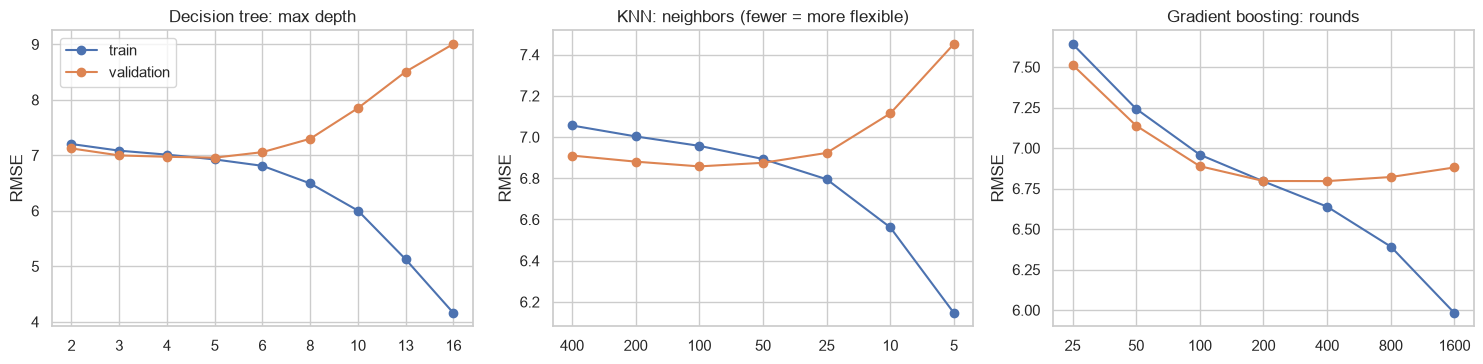

Decision tree: max depth,2,3,4,5,6,8,10,13,16
train,7.20,7.08,7.01,6.93,6.81,6.49,6.00,5.13,4.16
validation,7.12,7.00,6.97,6.96,7.06,7.30,7.85,8.51,9.01


KNN: neighbors (fewer = more flexible),400,200,100,50,25,10,5
train,7.06,7.00,6.96,6.89,6.80,6.56,6.15
validation,6.91,6.88,6.86,6.88,6.92,7.11,7.45


Gradient boosting: rounds,25,50,100,200,400,800,1600
train,7.64,7.24,6.96,6.79,6.64,6.39,5.98
validation,7.51,7.14,6.89,6.80,6.80,6.82,6.88


In [32]:
def train_valid_rmse(model):
    "Mean train and validation RMSE over the CV folds."
    rows = []
    for season, train, valid in cv_folds(train_features):
        fitted = clone(model).fit(train_features.loc[train, ALL_FEATURES], train_features.loc[train, TARGET])
        rows.append({name: np.sqrt(((fitted.predict(train_features.loc[idx, ALL_FEATURES]) - train_features.loc[idx, TARGET]) ** 2).mean())
                     for name, idx in [("train", train), ("validation", valid)]})
    return pd.DataFrame(rows).mean()


def complexity_curve(make_model, values):
    curve = Parallel(n_jobs=-1)(delayed(train_valid_rmse)(make_model(v)) for v in values)
    return pd.DataFrame(curve, index=values)


boosting_shape = {k: v for k, v in member_params["Gradient boosting"].items() if k != "max_iter"}
COMPLEXITY_CURVES = {
    "Decision tree: max depth": complexity_curve(
        lambda d: DecisionTreeRegressor(max_depth=d, random_state=SEED), [2, 3, 4, 5, 6, 8, 10, 13, 16]),
    "KNN: neighbors (fewer = more flexible)": complexity_curve(
        lambda k: scaled(KNeighborsRegressor(n_neighbors=k)), [400, 200, 100, 50, 25, 10, 5]),
    "Gradient boosting: rounds": complexity_curve(
        lambda n: make_boosting(**{**boosting_shape, "max_iter": n}), [25, 50, 100, 200, 400, 800, 1600]),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, curve) in zip(axes, COMPLEXITY_CURVES.items()):
    ax.plot(range(len(curve)), curve["train"], marker="o", label="train")
    ax.plot(range(len(curve)), curve["validation"], marker="o", label="validation")
    ax.set_xticks(range(len(curve)), curve.index)
    ax.set_title(title)
    ax.set_ylabel("RMSE")
axes[0].legend()
plt.tight_layout()
plt.show()
for title, curve in COMPLEXITY_CURVES.items():
    display(curve.T.round(2).rename_axis(title, axis=1))

**What we see:**
- **Tree:** validation RMSE is best at depth 5 (6.96). By depth 16 the train error falls to 4.16 while validation rises to 9.01.
- **KNN:** best at 100 neighbors (6.86). At 5 neighbors, train is 6.15 and validation 7.45.
- **Boosting:** validation is flat from 200 to 400 rounds (6.80) and creeps up to 6.88 at 1,600 rounds while train falls to 5.98. Our 300 rounds sit in the flat part.
- Weekly points are noisy, so flexible models start fitting noise quickly. The tuned settings from 6.2 sit at or next to the validation minimum in each curve.

### 6.6 Where are the errors?
Out-of-fold predictions from the chosen setup (voting ensemble, refit every week), split by position and by week of the season.
Bias is the mean of prediction minus actual. The untuned Ridge is shown for comparison.

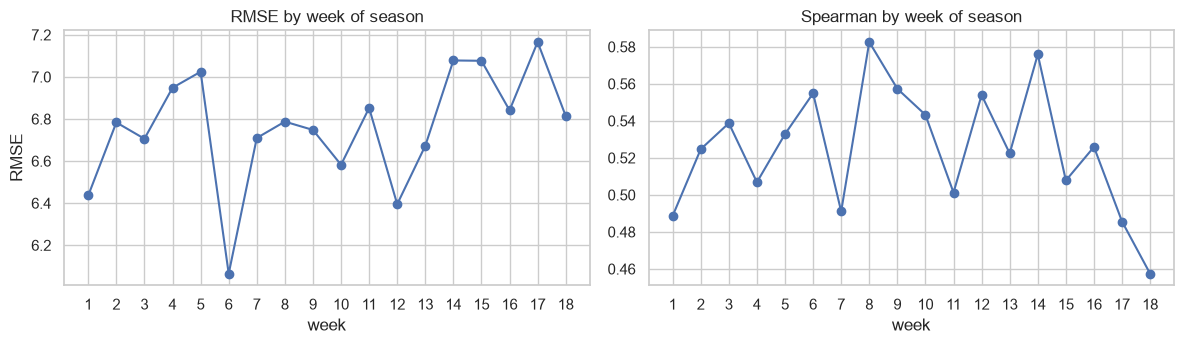

,player-weeks,mean points,rmse,mae,bias,spearman,ridge rmse,ridge spearman
QB,1726.0,14.680,7.457,5.976,-0.152,0.486,7.542,0.473
RB,2025.0,12.336,7.295,5.718,-0.282,0.473,7.341,0.464
WR,4927.0,9.535,6.958,5.326,-0.087,0.553,6.989,0.544
TE,2529.0,6.336,5.289,3.908,-0.157,0.588,5.321,0.577


,player-weeks,mean points,rmse,mae,bias,spearman,ridge rmse,ridge spearman
weeks 1-4,2691.0,9.711,6.722,5.136,0.010,0.515,6.747,0.508
weeks 5-18,8516.0,10.239,6.780,5.189,-0.198,0.528,6.828,0.517


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
rmse,6.436,6.784,6.706,6.948,7.024,6.065,6.710,6.787,6.748,6.582,6.852,6.395,6.673,7.078,7.077,6.841,7.166,6.814
spearman,0.489,0.525,0.539,0.507,0.533,0.555,0.491,0.583,0.557,0.543,0.501,0.554,0.522,0.576,0.508,0.526,0.486,0.457


In [33]:
chosen_oof = recency_oof[("Voting", "refit every week")]
ridge_oof = cross_validate(ridge, train_features, ALL_FEATURES)[1]
cv_rows = train_features[chosen_oof.notna()].assign(pred=chosen_oof, ridge_pred=ridge_oof)
cv_rows["error"] = cv_rows["pred"] - cv_rows[TARGET]


def error_summary(rows):
    scores = evaluate(rows, rows["pred"])
    return pd.Series({"player-weeks": len(rows), "mean points": rows[TARGET].mean(), "rmse": scores["rmse"],
                      "mae": scores["mae"], "bias": rows["error"].mean(), "spearman": scores["spearman"],
                      "ridge rmse": evaluate(rows, rows["ridge_pred"])["rmse"],
                      "ridge spearman": evaluate(rows, rows["ridge_pred"])["spearman"]})


errors_by_position = pd.DataFrame({p: error_summary(cv_rows[cv_rows["position"] == p]) for p in POSITIONS}).T
errors_by_week = pd.DataFrame({w: error_summary(rows) for w, rows in cv_rows.groupby("week")}).T
errors_by_stage = pd.DataFrame({name: error_summary(cv_rows[cv_rows["week"].between(lo, hi)])
                                for name, (lo, hi) in {"weeks 1-4": (1, 4), "weeks 5-18": (5, 18)}.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
errors_by_week["rmse"].plot(ax=axes[0], marker="o", title="RMSE by week of season", xlabel="week", ylabel="RMSE")
errors_by_week["spearman"].plot(ax=axes[1], marker="o", title="Spearman by week of season", xlabel="week")
for ax in axes:
    ax.set_xticks(errors_by_week.index)
plt.tight_layout()
plt.show()
display(errors_by_position.round(3), errors_by_stage.round(3), errors_by_week[["rmse", "spearman"]].T.round(3))

**What we see:**
- **By position:** point error is largest for QB (RMSE 7.46) and RB (7.30) and smallest for TE (5.29), who also score the least (6.3 points on average). Ranking is easiest for TE (Spearman 0.588) and WR (0.553) and hardest for RB (0.473) and QB (0.486).
- **Bias:** slightly negative everywhere (-0.09 to -0.28 points), so we under-predict a little, most for RB.
- **By week:** week 1 ranks poorly (Spearman 0.489, no games yet that season), and the last two weeks are the worst (0.486 and 0.457), when teams rest or lose starters. RMSE moves between 6.1 and 7.2 with no clear trend.
- Early weeks (1-4) rank slightly worse than later weeks (0.515 vs. 0.528) with about the same RMSE (6.72 vs. 6.78).
- Voting beats the untuned Ridge in every position and in both parts of the season.

### 6.7 Model comparison
All results in one table, best rank correlation first. The last row of 6.4 (voting, refit every week) is the chosen setup.

In [34]:
comparison = pd.concat([
    bar_to_beat.rename(index={"Ridge, untuned (5.8)": "Ridge, untuned"}),
    best_per_model.drop(columns="params"),
    combine_results.loc[["Voting (average of the three)", "Stacking (Ridge on top of the three)"], bar_to_beat.columns],
    pd.DataFrame({"Voting, refit every week (chosen)":
                  evaluate(train_features[chosen_oof.notna()], chosen_oof[chosen_oof.notna()])}).T,
]).sort_values(SELECT_METRIC, ascending=False).round(4)
comparison

,rmse,mae,spearman,top12_hit_rate
"Voting, refit every week (chosen)",6.7658,5.1766,0.5251,0.4888
Voting (average of the three),6.7651,5.1705,0.5247,0.4900
Stacking (Ridge on top of the three),6.7681,5.1810,0.5246,0.4919
MLP,6.7801,5.1746,0.5227,0.4977
Polynomial (degree 2) + Lasso,6.7937,5.2131,0.5190,0.4896
Gradient boosting,6.7919,5.2113,0.5189,0.4888
SVM (RBF kernel),6.8673,5.1250,0.5165,0.4927
Lasso,6.8025,5.1929,0.5157,0.4888
Ridge,6.8056,5.1942,0.5151,0.4900
"Ridge, untuned",6.8090,5.1939,0.5146,0.4896


**What we see:**
- **Chosen model:** the voting ensemble (Lasso + gradient boosting + MLP), trained on all earlier seasons with equal weights and refit every week: RMSE 6.766, MAE 5.177, Spearman 0.525, top-12 hit rate 0.489.
- Against the last-3 average it cuts RMSE by 0.83 and adds 0.10 Spearman. Against the untuned Ridge the gain is small: RMSE -0.043, Spearman +0.011.
- The top-12 hit rate does not improve (0.489 vs. 0.490 for Ridge). The gain is in ordering the whole list, not in who lands in the top 12.
- So most of the predictive power comes from the features (section 5); model choice and tuning add a small, consistent gain on top.

### 6.8 Saved predictions and settings
Tiers (section 7), clustering (section 8), and the final test (section 9) use the chosen model's out-of-fold predictions and settings, saved to two files:
- `preds_regression.parquet`: one prediction per player-week in the CV seasons (2022-2024), made by a model that only saw games before that week
- `regression_choice.json`: the model and settings, so section 9 can rebuild the same model for 2025

In [35]:
import json

REGRESSION_CHOICE = {
    "status": "final",
    "model": "Voting (Lasso + gradient boosting + MLP)",
    "params": member_params,                    # each member's tuned settings from 6.2
    "features": ALL_FEATURES,
    "training_window": "all seasons before the predicted week",
    "sample_weight_half_life_seasons": None,    # None = every season counts the same
    "refit": "every week",
}


def make_regression_model(choice):
    return make_vote(choice["params"])


def save_regression_outputs(data, choice):
    scores, oof = cross_validate_recency(make_regression_model(choice), data, choice["features"],
                                         half_life=choice["sample_weight_half_life_seasons"],
                                         refit_weekly=choice["refit"] == "every week")
    scored = oof.notna()
    preds = data.loc[scored, KEY + ["position"]].assign(pred=oof[scored], model=choice["model"])
    preds.to_parquet(PROCESSED_DIR / "preds_regression.parquet", index=False)
    (PROCESSED_DIR / "regression_choice.json").write_text(json.dumps(choice, indent=2))
    return preds, scores


regression_preds, regression_scores = save_regression_outputs(train_features, REGRESSION_CHOICE)
assert np.allclose(regression_preds["pred"], chosen_oof[chosen_oof.notna()]), "saved predictions differ from 6.4"
print(f"Saved {len(regression_preds):,} out-of-fold predictions "
      f"({regression_preds['season'].min()}-{regression_preds['season'].max()})")
print("Member settings:", REGRESSION_CHOICE["params"])
pd.Series(regression_scores).round(4).to_frame("CV score")

Saved 11,207 out-of-fold predictions (2022-2024)
Member settings: {'Lasso': {'alpha': 0.01}, 'Gradient boosting': {'max_iter': 300, 'learning_rate': 0.02, 'max_leaf_nodes': 8, 'min_samples_leaf': 40}, 'MLP': {'hidden_layer_sizes': (64, 32), 'alpha': 30}}


,CV score
rmse,6.7658
mae,5.1766
spearman,0.5251
top12_hit_rate,0.4888


**What we see:**
- 11,207 out-of-fold predictions for 2022-2024. Their scores equal the chosen row in 6.7 (RMSE 6.766, Spearman 0.525), and the cell checks that they match the predictions analyzed in 6.6.

## 7. Tiers (extension)
Sections 7 and 8 are the two extensions. The main task continues in section 9, where the model from section 6 is tested on 2025.

Tiers come from points, so does a classifier that predicts tiers directly do any better than tiers cut from our points regression?
- **Tiers (fixed, not tuned):** within each position-week, rank players by actual PPR points. Tier 1 = ranks 1-12 (a starter in a 12-team league), tier 2 = ranks 13-24, tier 3 = everyone else.
- **Three ways to predict a tier:** cut our regression's predicted ranks at the same places, train a classifier on the same 48 features to predict the tier directly, and cut the experts' ranks (ECR).
- **Scoring:** macro F1 (each tier counts equally, so the large tier 3 cannot dominate), computed inside each position-week and then averaged, the same way Spearman is in 5.6. Also precision and recall per tier, and confusion matrices.
- **Data:** the CV seasons 2022-2024 only. 2025 is not used here, and nothing in this section changes the regression.

### 7.1 Tier labels and tiers cut from the regression
Actual tiers come from each week's real points. The regression's tiers come from cutting its saved out-of-fold predictions (6.8) at the same ranks.

In [36]:
TIERS = [1, 2, 3]


def cut_tiers(rows, score):
    "Tier 1, 2, or 3 from the rank of `score` within each position-week (highest score = rank 1)."
    rank = rows.groupby(["season", "week", "position"])[score].rank(ascending=False, method="first")
    return np.select([rank <= TIER_CUTS[0], rank <= TIER_CUTS[1]], [1, 2], default=3)


saved_regression = pd.read_parquet(PROCESSED_DIR / "preds_regression.parquet")
tier_rows = train_features.assign(tier_actual=cut_tiers(train_features, TARGET))
tier_rows["pred"] = tier_rows[KEY].merge(saved_regression, on=KEY, how="left", validate="one_to_one")["pred"].to_numpy()
tier_cv = tier_rows[tier_rows["season"].isin(CV_VALID_SEASONS)].copy()
assert tier_cv["pred"].notna().all(), "every CV player-week needs a regression prediction"
tier_cv["tier_from_regression"] = cut_tiers(tier_cv, "pred")

print(f"{len(tier_cv):,} player-weeks in {CV_VALID_SEASONS[0]}-{CV_VALID_SEASONS[-1]}. Share of each position in each tier:")
pd.crosstab(tier_cv["position"], tier_cv["tier_actual"], normalize="index").loc[POSITIONS].round(3).add_prefix("tier ")

11,207 player-weeks in 2022-2024. Share of each position in each tier:


tier_actual,tier 1,tier 2,tier 3
position,,,
QB,0.375,0.375,0.249
RB,0.320,0.320,0.360
WR,0.132,0.132,0.737
TE,0.256,0.256,0.488


**What we see:**
- The tiers are imbalanced, and how much depends on the position. A position-week has about 32 QBs but 91 WRs, so tier 1 holds 37% of QBs but only 13% of WRs, and tier 3 holds 74% of WRs.
- Overall, tier 3 is the largest class. A classifier that ignores imbalance will lean toward it, so we compare class weighting against none and score with macro F1.

### 7.2 A classifier that predicts the tier directly
Three course classifiers, each with a small grid, with and without `class_weight="balanced"` (each tier weighted by the inverse of its size).
Tuning uses the season folds from `cv_folds()` and picks the highest macro F1 (within position-week). The winner is then refit every week, like the regression,
so both methods learn from the same games.

In [37]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support

TIER_MODELS = {
    "Logistic regression": lambda **p: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, **p)),
    "Random forest": lambda **p: RandomForestClassifier(n_estimators=300, random_state=SEED, **p),
    "Gradient boosting": lambda **p: HistGradientBoostingClassifier(max_iter=300, max_leaf_nodes=8, random_state=SEED, **p),
}
TIER_GRIDS = {"Logistic regression": ("C", [0.01, 0.1, 1.0]),            # one setting tuned per model
              "Random forest": ("min_samples_leaf", [10, 30, 100]),
              "Gradient boosting": ("learning_rate", [0.02, 0.05, 0.1])}
CLASS_WEIGHTS = {"no weighting": None, "balanced": "balanced"}


def tier_splits(data, refit_weekly):
    "(training rows, rows to predict) pairs for the CV seasons. Training rows are always from earlier games."
    for season, train, valid in cv_folds(data):
        earlier, this_season = data.loc[train], data.loc[valid]
        if not refit_weekly:
            yield earlier, this_season
            continue
        for week in sorted(this_season["week"].unique()):
            yield pd.concat([earlier, this_season[this_season["week"] < week]]), this_season[this_season["week"] == week]


def fit_and_predict_tiers(model, fit_rows, predict_rows):
    fitted = clone(model).fit(fit_rows[ALL_FEATURES], fit_rows["tier_actual"])
    return pd.DataFrame(fitted.predict_proba(predict_rows[ALL_FEATURES]), index=predict_rows.index, columns=fitted.classes_)


def tier_probabilities(model, data, refit_weekly=False):
    "Out-of-fold probability of each tier for every CV player-week."
    blocks = Parallel(n_jobs=-1)(delayed(fit_and_predict_tiers)(model, fit_rows, predict_rows)
                                 for fit_rows, predict_rows in tier_splits(data, refit_weekly))
    return pd.concat(blocks).sort_index()


def macro_f1(actual, predicted):
    return f1_score(actual, predicted, labels=TIERS, average="macro", zero_division=0)


def position_week_macro_f1(rows, column):
    "Macro F1 inside each position-week, where the tiers are defined. One value per position-week."
    return rows.groupby(["season", "week", "position"]).apply(lambda w: macro_f1(w["tier_actual"], w[column]))


tuning_rows = []
for name, (param, values) in TIER_GRIDS.items():
    for value in values:
        for weighting, class_weight in CLASS_WEIGHTS.items():
            probs = tier_probabilities(TIER_MODELS[name](class_weight=class_weight, **{param: value}), tier_rows)
            scored = tier_rows.loc[probs.index].assign(tier_pred=probs.idxmax(axis=1))
            tuning_rows.append({"model": name, "setting": f"{param}={value}", "params": {param: value},
                                "weighting": weighting, "macro F1": position_week_macro_f1(scored, "tier_pred").mean()})
tier_tuning = pd.DataFrame(tuning_rows)

best = tier_tuning.loc[tier_tuning["macro F1"].idxmax()]
TIER_CHOICE = {"model": best["model"], "params": best["params"], "class_weight": CLASS_WEIGHTS[best["weighting"]],
               "refit": "every week", "tier_cuts": TIER_CUTS}
print("Chosen:", TIER_CHOICE)
tier_tuning.pivot_table(index=["model", "setting"], columns="weighting", values="macro F1", sort=False).round(4)

Chosen: {'model': 'Gradient boosting', 'params': {'learning_rate': 0.1}, 'class_weight': 'balanced', 'refit': 'every week', 'tier_cuts': [12, 24]}


weighting                                 no weighting  balanced
model               setting                                     
Logistic regression C=0.01                      0.4327    0.4478
                    C=0.1                       0.4367    0.4495
                    C=1.0                       0.4351    0.4504
Random forest       min_samples_leaf=10         0.4332    0.4418
                    min_samples_leaf=30         0.4276    0.4400
                    min_samples_leaf=100        0.4205    0.4360
Gradient boosting   learning_rate=0.02          0.4309    0.4541
                    learning_rate=0.05          0.4340    0.4510
                    learning_rate=0.1           0.4324    0.4591

**What we see:**
- Balanced class weights beat no weighting for every model and setting, by 0.009 to 0.027 macro F1. So the weighting stays.
- The three models are close. The best setting is 0.459 for gradient boosting, 0.450 for logistic regression, and 0.442 for random forest. Gradient boosting (learning rate 0.1, balanced) is chosen.

In [38]:
tier_model = TIER_MODELS[TIER_CHOICE["model"]](class_weight=TIER_CHOICE["class_weight"], **TIER_CHOICE["params"])
tier_probs = tier_probabilities(tier_model, tier_rows, refit_weekly=True)
assert tier_probs.index.equals(tier_cv.index)

# Raw labels: the most likely tier for each player, judged on its own.
tier_cv["tier_classifier"] = tier_probs.idxmax(axis=1)
# Quota version: rank players by expected tier (lower is better), then cut at 12 and 24 like the regression.
tier_cv["classifier_score"] = -(tier_probs * TIERS).sum(axis=1)
tier_cv["tier_classifier_quota"] = cut_tiers(tier_cv, "classifier_score")

print("Players per position-week the raw labels put in each tier (the actual tiers always hold 12, 12, and the rest):")
(tier_cv.groupby(["season", "week", "position"])["tier_classifier"].value_counts().unstack(fill_value=0)
 .groupby("position").mean().loc[POSITIONS].round(1).add_prefix("tier "))

Players per position-week the raw labels put in each tier (the actual tiers always hold 12, 12, and the rest):


tier_classifier,tier 1,tier 2,tier 3
position,,,
QB,10.4,19.1,2.4
RB,15.0,17.9,4.6
WR,12.4,2.2,76.7
TE,13.5,13.5,19.8


**What we see:**
- The raw labels do not keep the tier sizes. Each player is judged alone, so the classifier puts only 2.4 QBs per week in tier 3 (the real number is about 8) and only 2.2 WRs in tier 2 (the real number is 12).
- The reason: a middling WR is still more likely to land in tier 3 than tier 2, so tier 2 is rarely the most likely label for that player. A ranking does not have this problem, because it compares each player with the rest of that week.

### 7.3 Regression cut vs. classifier
All 11,207 CV player-weeks. The verdict uses each week's macro F1 (averaged over the four positions). We bootstrap the weekly gap between
the regression cut and the classifier's raw labels to get a 95% interval. Pooled macro F1 (all positions in one pile) is shown next to it
to make a point in the notes below. Precision, recall, and the confusion matrices are pooled.

,macro F1,pooled macro F1,accuracy,tier 1 precision,tier 2 precision,tier 3 precision,tier 1 recall,tier 2 recall,tier 3 recall
cut from regression,0.495,0.526,0.596,0.489,0.335,0.755,0.489,0.335,0.755
classifier (raw labels),0.454,0.536,0.594,0.466,0.366,0.773,0.498,0.402,0.717
classifier (quota cut),0.491,0.524,0.592,0.484,0.342,0.746,0.484,0.342,0.746


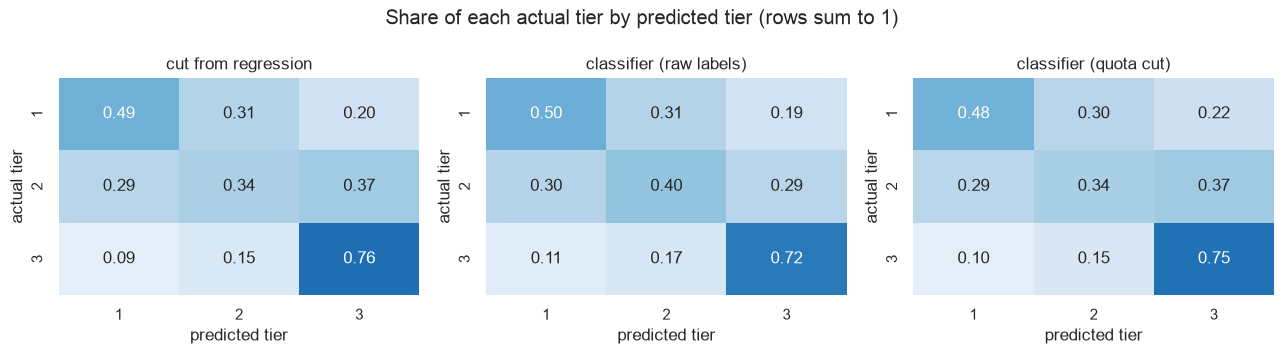

Weekly macro F1, regression cut minus classifier: +0.040 (95% interval +0.031 to +0.049); regression ahead in 47 of 54 weeks


In [39]:
TIER_METHODS = {"cut from regression": "tier_from_regression",
                "classifier (raw labels)": "tier_classifier",
                "classifier (quota cut)": "tier_classifier_quota"}


def tier_scores(rows, column):
    actual, predicted = rows["tier_actual"], rows[column]
    precision, recall, _, _ = precision_recall_fscore_support(actual, predicted, labels=TIERS, zero_division=0)
    return {"macro F1": position_week_macro_f1(rows, column).mean(), "pooled macro F1": macro_f1(actual, predicted),
            "accuracy": accuracy_score(actual, predicted),
            **{f"tier {t} precision": p for t, p in zip(TIERS, precision)},
            **{f"tier {t} recall": r for t, r in zip(TIERS, recall)}}


def weekly_macro_f1(rows, column):
    "Each week's macro F1, averaged over the four positions."
    return position_week_macro_f1(rows, column).groupby(["season", "week"]).mean()


def bootstrap_interval(values):
    rng = np.random.default_rng(SEED)
    means = [rng.choice(values, len(values)).mean() for _ in range(BOOTSTRAP_DRAWS)]
    return np.percentile(means, [2.5, 97.5])


tier_comparison = pd.DataFrame({name: tier_scores(tier_cv, column) for name, column in TIER_METHODS.items()}).T
display(tier_comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, column) in zip(axes, TIER_METHODS.items()):
    matrix = confusion_matrix(tier_cv["tier_actual"], tier_cv[column], labels=TIERS, normalize="true")
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=TIERS, yticklabels=TIERS)
    ax.set(title=name, xlabel="predicted tier", ylabel="actual tier")
plt.suptitle("Share of each actual tier by predicted tier (rows sum to 1)")
plt.tight_layout()
plt.show()

weekly_gap = weekly_macro_f1(tier_cv, "tier_from_regression") - weekly_macro_f1(tier_cv, "tier_classifier")
low, high = bootstrap_interval(weekly_gap.to_numpy())
print(f"Weekly macro F1, regression cut minus classifier: {weekly_gap.mean():+.3f} "
      f"(95% interval {low:+.3f} to {high:+.3f}); regression ahead in {(weekly_gap > 0).sum()} of {len(weekly_gap)} weeks")

**What we see:**
- **The regression cut wins.** Macro F1 within position-week is 0.495 for the regression cut and 0.454 for the classifier. The weekly gap is +0.040 (95% interval +0.031 to +0.049), and the regression is ahead in 47 of 54 weeks.
- **Pooled macro F1 points the wrong way** (0.536 for the classifier vs. 0.526). Pooling rewards knowing that QBs usually land in tiers 1-2 and WRs in tier 3. That is true but useless, because tiers are only compared within a position.
- **Turning the classifier into a ranking closes the gap.** The quota cut scores 0.491, almost the same as the regression (0.495). The classifier's information is about the same; it loses because of how it sizes the tiers.
- **Tier 2 is the hardest for every method** (recall 0.34 to 0.40), since it borders both other tiers. Tier 1 recall for the regression cut (0.489) is the same number as its top-12 hit rate in section 6.

### 7.4 Against the experts
Same rules as the final test: keep player-weeks with an expert rank made before kickoff, then re-cut every rank-based tier
(actual, regression, classifier quota, ECR) within those rows so all methods are judged on the same players. Macro F1 by position:

In [40]:
def macro_f1_by_position(rows, column):
    scores = position_week_macro_f1(rows, column)
    return {"all": scores.mean(), **scores.groupby("position").mean()}


saved_ecr = pd.read_parquet(PROCESSED_DIR / "ecr_weekly.parquet")
usable_ecr = saved_ecr.loc[~saved_ecr["played_before_snapshot"], KEY + ["ecr_pos_rank"]]
tier_matched = tier_cv.merge(usable_ecr, on=KEY, validate="one_to_one").assign(
    ecr_score=lambda d: -d["ecr_pos_rank"])
tier_matched["tier_actual"] = cut_tiers(tier_matched, TARGET)
tier_matched["tier_ecr"] = cut_tiers(tier_matched, "ecr_score")
for column, score in [("tier_from_regression", "pred"), ("tier_classifier_quota", "classifier_score")]:
    tier_matched[column] = cut_tiers(tier_matched, score)

MATCHED_METHODS = {**TIER_METHODS, "cut from ECR": "tier_ecr"}
expert_comparison = pd.DataFrame({name: macro_f1_by_position(tier_matched, column)
                                  for name, column in MATCHED_METHODS.items()}).T[["all"] + POSITIONS]
print(f"{len(tier_matched):,} player-weeks with a usable expert rank")
expert_comparison.round(3)

8,565 player-weeks with a usable expert rank


,all,QB,RB,WR,TE
cut from regression,0.499,0.494,0.492,0.475,0.536
classifier (raw labels),0.459,0.438,0.458,0.410,0.528
classifier (quota cut),0.493,0.487,0.489,0.460,0.537
cut from ECR,0.508,0.517,0.501,0.484,0.531


**What we see:**
- The experts are a little ahead: 0.508 for ECR vs. 0.499 for the regression cut, on 8,565 player-weeks.
- By position, the experts lead at QB (0.517 vs. 0.494), RB (0.501 vs. 0.492), and WR (0.484 vs. 0.475), and we lead at TE (0.536 vs. 0.531). This is the same pattern as the Spearman results in section 9.
- The classifier's raw labels are last at every position (0.410 to 0.528).

### 7.5 Saved tiers and the answer
`tier_results.parquet` has one row per CV player-week. `tier_actual`, `tier_from_regression`, and `tier_classifier` use the full player pool.
`tier_ecr` is filled only where a usable expert rank exists, and is cut within those rows (as in 7.4). `tier_choice.json` stores the
classifier settings and the 7.3 macro F1 scores.

In [41]:
tier_results = tier_cv[KEY + ["position", "tier_actual", "tier_from_regression", "tier_classifier"]].merge(
    tier_matched[KEY + ["tier_ecr"]], on=KEY, how="left", validate="one_to_one")
tier_results["tier_ecr"] = tier_results["tier_ecr"].astype("Int64")
tier_results.to_parquet(PROCESSED_DIR / "tier_results.parquet", index=False)
(PROCESSED_DIR / "tier_choice.json").write_text(json.dumps(
    {**TIER_CHOICE, "macro_f1": tier_comparison["macro F1"].round(6).to_dict()}, indent=2))
print(f"Saved {len(tier_results):,} rows; {tier_results['tier_ecr'].notna().sum():,} have an ECR tier")

Saved 11,207 rows; 8,565 have an ECR tier


**Answer:** a separate tier classifier does not beat tiers cut from our points regression. On 2022-2024, the regression cut scores macro F1 0.495 and the best tuned classifier (gradient boosting with balanced class weights) scores 0.454. The regression cut is ahead in 47 of 54 weeks (gap +0.040, 95% interval +0.031 to +0.049). When we turn the classifier's probabilities into a ranking and cut it at the same places, it scores 0.491, about the same as the regression. So tiers are a coarse version of the points ranking and carry the same information. The classifier only differs in how it fills the tiers, and it does that worse because it judges each player alone instead of against the rest of that week. That is why the points regression is our main task, and tiers are an extension read off it. Against the experts, tiers cut from ECR score 0.508 vs. our 0.499, the same small expert edge as in section 9.

## 8. Usage clustering (extension)
Goal: group players into usage profiles that reflect their current role, describe them, and test whether they help the regression.
- **Inputs:** the recent usage features only (last 3 games and recency-weighted). No points and no expert ranks.
- **Data:** 2020-2024 only. Profiles are chosen on 2020-2021, the seasons no CV fold validates on.
- **Selection rule, set before the comparison:** pick the K-Means k with the best silhouette. K-Means can assign later players to fixed centers without refitting; Ward and DBSCAN cannot, so they are shown for comparison only.

### 8.1 Compare clustering methods
K-Means, Ward (hierarchical), and DBSCAN on the same standardized sample of 2,500 player-weeks from 2020-2021.
Silhouette is higher when clusters are tight and far apart; Davies-Bouldin is lower. DBSCAN marks some points as noise,
so `coverage` shows the share it actually clusters.

Chosen: K-Means k=4


,clusters,coverage,silhouette,davies_bouldin
method,,,,
K-Means k=3,3,1.000,0.396,0.955
K-Means k=4,4,1.000,0.480,0.732
K-Means k=5,5,1.000,0.398,0.870
K-Means k=6,6,1.000,0.379,0.968
Ward k=3,3,1.000,0.481,0.808
Ward k=4,4,1.000,0.433,0.797
Ward k=5,5,1.000,0.369,0.885
Ward k=6,6,1.000,0.359,0.962
DBSCAN eps=0.5,2,0.228,0.823,0.252


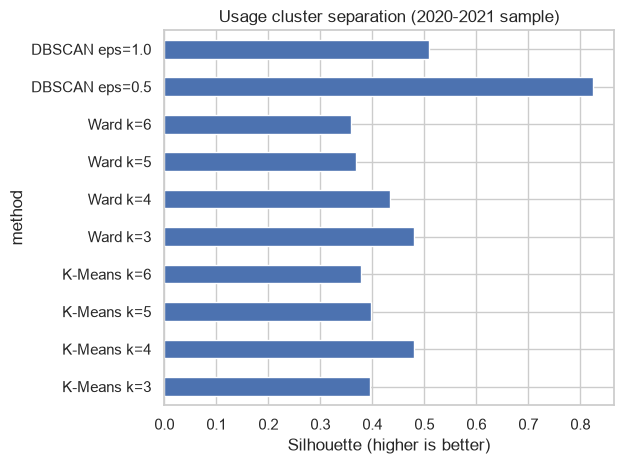

In [42]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score

PROFILE_COLUMNS = [c for c in FEATURE_FAMILIES["usage"] if c.endswith(("_last3", "_recent"))]
usage_rows = features[features["season"].isin(TRAIN_SEASONS)].sort_values(KEY).reset_index(drop=True)
usage_initial = usage_rows[usage_rows["season"] < CV_VALID_SEASONS[0]]      # 2020-2021
assert usage_rows["season"].max() < TEST_SEASON
assert PROFILE_COLUMNS and not any("ecr" in c or "points" in c for c in PROFILE_COLUMNS)

usage_scaler = StandardScaler().fit(usage_initial[PROFILE_COLUMNS])
cluster_sample = usage_initial.sample(min(CLUSTER_SAMPLE_SIZE, len(usage_initial)), random_state=SEED)
sample_scaled = usage_scaler.transform(cluster_sample[PROFILE_COLUMNS])

CLUSTER_METHODS = {
    **{f"K-Means k={k}": KMeans(n_clusters=k, n_init=10, random_state=SEED) for k in CLUSTER_K_CANDIDATES},
    **{f"Ward k={k}": AgglomerativeClustering(n_clusters=k) for k in CLUSTER_K_CANDIDATES},
    **{f"DBSCAN eps={eps}": DBSCAN(eps=eps, min_samples=DBSCAN_MIN_SAMPLES) for eps in DBSCAN_EPS_CANDIDATES},
}


def cluster_quality(model, x):
    "Validation scores for one clustering. DBSCAN noise points (label -1) are left out of the scores."
    labels = model.fit_predict(x)
    clustered = labels != -1
    n_clusters = len(set(labels[clustered]))
    scorable = 1 < n_clusters < clustered.sum()
    return {"clusters": n_clusters, "coverage": clustered.mean(),
            "silhouette": silhouette_score(x[clustered], labels[clustered]) if scorable else np.nan,
            "davies_bouldin": davies_bouldin_score(x[clustered], labels[clustered]) if scorable else np.nan}


cluster_comparison = pd.DataFrame([{"method": name, **cluster_quality(model, sample_scaled)}
                                   for name, model in CLUSTER_METHODS.items()]).set_index("method")
best_kmeans = cluster_comparison.loc[cluster_comparison.index.str.startswith("K-Means"), "silhouette"].idxmax()
N_PROFILES = int(best_kmeans.split("=")[1])
print(f"Chosen: {best_kmeans}")
display(cluster_comparison.round(3))

cluster_comparison["silhouette"].plot.barh(title="Usage cluster separation (2020-2021 sample)",
                                           xlabel="Silhouette (higher is better)")
plt.tight_layout()
plt.show()

**What we see:**
- **K-Means with k=4 is chosen.** It has the best silhouette (0.480) and the best Davies-Bouldin (0.732) of the K-Means settings; k=3, 5, and 6 score 0.379 to 0.398.
- Ward with k=3 is level with it (0.481), so the grouping does not depend much on the method.
- DBSCAN with eps=0.5 has the highest silhouette (0.823) but clusters only 22.8% of the sample and calls the rest noise, so that score is not comparable. With eps=1.0 it covers 94.0% and finds 3 clusters (0.509).
- These are role groups, not scoring tiers.

### 8.2 The profiles and how often players switch
K-Means with the chosen k is fit once on 2020-2021, and every 2020-2024 player-week is assigned to the nearest of those
centers. So cluster numbers mean the same thing in every season. A switch is a player whose profile differs from their
previous row in the pool (their first row is never a switch).

Players switch profile on 5.7% of 17,645 week-to-week transitions


,snap_share_last3,target_share_last3,carry_share_last3,air_yards_share_last3,opportunities_last3
cluster,,,,,
0,0.94,0.00,0.14,0.00,35.89
1,0.80,0.22,0.01,0.28,7.22
2,0.60,0.10,0.52,-0.00,17.43
3,0.57,0.09,0.01,0.09,3.73


position,QB,RB,WR,TE
cluster,,,,
0,2647,0,0,0
1,0,0,5026,1090
2,13,2876,0,1
3,169,417,3097,3066


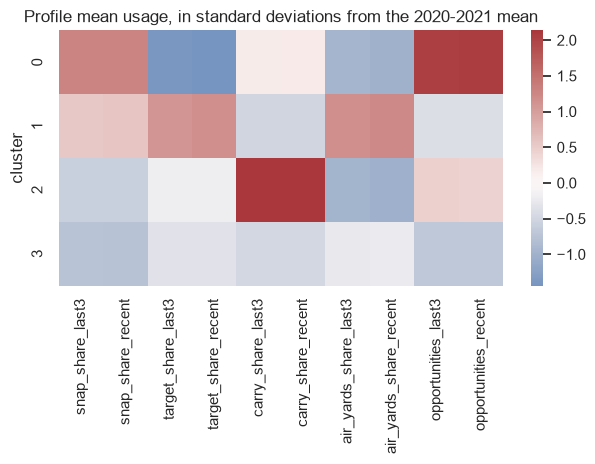

In [43]:
profile_model = make_pipeline(StandardScaler(), KMeans(n_clusters=N_PROFILES, n_init=10, random_state=SEED))
profile_model.fit(usage_initial[PROFILE_COLUMNS])

cluster = pd.Series(profile_model.predict(usage_rows[PROFILE_COLUMNS]), index=usage_rows.index, name="cluster")
previous_cluster = cluster.groupby(usage_rows["gsis_id"]).shift(1)
switched = previous_cluster.notna() & cluster.ne(previous_cluster)
usage_clusters = usage_rows[KEY].assign(cluster=cluster, switched_cluster=switched)
usage_clusters.to_parquet(PROCESSED_DIR / "usage_clusters.parquet", index=False)

profile_means = usage_rows[PROFILE_COLUMNS].groupby(cluster).mean()
profile_positions = pd.crosstab(cluster, usage_rows["position"]).reindex(columns=POSITIONS, fill_value=0)
print(f"Players switch profile on {switched[previous_cluster.notna()].mean():.1%} "
      f"of {previous_cluster.notna().sum():,} week-to-week transitions")
display(profile_means[[c for c in PROFILE_COLUMNS if c.endswith("_last3")]].round(2), profile_positions)

profile_z_scores = pd.DataFrame(usage_scaler.transform(profile_means), index=profile_means.index, columns=PROFILE_COLUMNS)
sns.heatmap(profile_z_scores, cmap="vlag", center=0)
plt.title("Profile mean usage, in standard deviations from the 2020-2021 mean")
plt.tight_layout()
plt.show()

**What we see:**
- **Cluster 0, passers:** all 2,647 rows are QBs. Snap share 0.94 and 35.9 opportunities a game over the last 3.
- **Cluster 1, high-volume receivers:** 5,026 WR and 1,090 TE rows. Target share 0.22, air-yards share 0.28, snap share 0.80.
- **Cluster 2, rushing backs:** 2,876 of its 2,890 rows are RBs. Carry share 0.52 and 17.4 opportunities.
- **Cluster 3, low-volume receivers:** 3,097 WR and 3,066 TE rows, plus 417 RBs and 169 QBs with small roles. Target share 0.09 and 3.7 opportunities.
- **Switching is rare:** players change profile on 5.7% of 17,645 week-to-week transitions. The usage windows overlap from one week to the next, so a profile changes slowly.
- The profiles mostly follow position, but they also split receivers by volume, and WRs and TEs share both receiver profiles.
- Labels for 2020-2021 are in-sample; 2022-2024 are assigned to centers fit on earlier seasons. Nothing is saved for 2025.

### 8.3 Do the profiles help the regression?
We add the profile (one flag per cluster) and a switch flag to the 48 features and rerun the frozen regression from section 6.
- **No leakage:** the scaler and the centers are refit inside every training fold or week, by a transformer placed in front of the model.
- **Switch flag:** cluster numbers can change from one refit to the next, so each row carries its usage at the player's previous row. Both the current and previous usage are assigned under the same centers, and the flag is 1 when they differ.
- **Comparison:** with vs. without, fit once per season and refit every week. The weekly "without" row is the saved section 6 predictions.

This was run after the model was frozen, so it cannot change the final model or the 2025 verdict.

In [44]:
PREVIOUS_COLUMNS = [f"previous_{c}" for c in PROFILE_COLUMNS]
previous_usage = usage_rows.groupby("gsis_id")[PROFILE_COLUMNS].shift(1).fillna(usage_rows[PROFILE_COLUMNS])
usage_rows[PREVIOUS_COLUMNS] = previous_usage.to_numpy()        # a player's first row gets its own usage (no switch)
usage_rows["has_previous"] = previous_cluster.notna().astype(int)
profile_inputs = ALL_FEATURES + PREVIOUS_COLUMNS + ["has_previous"]


class UsageProfiles(BaseEstimator, TransformerMixin):
    "Adds one flag per usage profile and a switch flag to the base features. The profiles are learned in fit() only."

    def __init__(self, usage_columns, base_columns, n_clusters, seed):
        self.usage_columns = usage_columns
        self.base_columns = base_columns
        self.n_clusters = n_clusters
        self.seed = seed

    def fit(self, X, y=None):
        self.profiles_ = make_pipeline(StandardScaler(), KMeans(n_clusters=self.n_clusters, n_init=10, random_state=self.seed))
        self.profiles_.fit(X[self.usage_columns])
        return self

    def transform(self, X):
        labels = self.profiles_.predict(X[self.usage_columns])
        previous = X[[f"previous_{c}" for c in self.usage_columns]].copy()
        previous.columns = self.usage_columns
        previous_labels = self.profiles_.predict(previous)
        switched = (labels != previous_labels) & X["has_previous"].to_numpy().astype(bool)
        return np.column_stack([X[self.base_columns], np.eye(self.n_clusters)[labels], switched.astype(int)])


regression_choice = json.loads((PROCESSED_DIR / "regression_choice.json").read_text())
assert regression_choice["status"] == "final" and regression_choice["refit"] == "every week"
with_profiles = make_pipeline(UsageProfiles(PROFILE_COLUMNS, ALL_FEATURES, N_PROFILES, SEED),
                              make_regression_model(regression_choice))

plain_annual, _ = cross_validate(make_regression_model(regression_choice), usage_rows, ALL_FEATURES)
profiles_annual, _ = cross_validate(with_profiles, usage_rows, profile_inputs)
profiles_weekly, profiles_oof = cross_validate_recency(with_profiles, usage_rows, profile_inputs, refit_weekly=True)
saved_rows = usage_rows.merge(saved_regression[KEY + ["pred"]], on=KEY, validate="one_to_one")
plain_weekly = evaluate(saved_rows, saved_rows["pred"])

profile_results = pd.DataFrame({"annual: original": plain_annual, "annual: clusters + switch": profiles_annual,
                                "weekly: original": plain_weekly, "weekly: clusters + switch": profiles_weekly}).T
profile_results.round(4)

,rmse,mae,spearman,top12_hit_rate
annual: original,6.7651,5.1705,0.5247,0.4900
annual: clusters + switch,6.7710,5.1804,0.5231,0.4911
weekly: original,6.7658,5.1766,0.5251,0.4888
weekly: clusters + switch,6.7664,5.1805,0.5254,0.4892


**What we see:**
- **Refit every week (the chosen cadence):** Spearman is 0.5254 with the profiles and 0.5251 without, and RMSE is 6.766 for both.
- **Fit once per season:** slightly worse with the profiles (Spearman 0.523 vs. 0.525, RMSE 6.771 vs. 6.765).
- Differences this small are noise: the MLP alone moves by a few thousandths with its random seed (6.3). The profiles are built from features the model already has, so they add a new view of the same information, not new information.
- **Decision:** the profiles stay descriptive and are not added to the model. The frozen regression and the 2025 predictions are unchanged.

Save the profile labels, the out-of-fold predictions with profiles, the table above, and the clustering settings.

In [45]:
scored = profiles_oof.notna()
profile_predictions = usage_rows.loc[scored, KEY + ["position", TARGET]].assign(pred=profiles_oof[scored])
profile_predictions.to_parquet(PROCESSED_DIR / "usage_cluster_cv_predictions.parquet", index=False)
profile_results.to_csv(PROCESSED_DIR / "usage_cluster_comparison.csv")
(PROCESSED_DIR / "usage_cluster_choice.json").write_text(json.dumps({
    "k": N_PROFILES, "usage_columns": PROFILE_COLUMNS,
    "selection_seasons": [s for s in TRAIN_SEASONS if s < CV_VALID_SEASONS[0]],
    "evaluation_seasons": CV_VALID_SEASONS, "export_seasons": TRAIN_SEASONS,
    "selection_rule": "best K-Means silhouette on initial training sample", "changes_frozen_regression": False}, indent=2))
print(f"Saved {len(usage_clusters):,} profile labels and {len(profile_predictions):,} out-of-fold predictions with profiles")

Saved 18,402 profile labels and 11,207 out-of-fold predictions with profiles


## 9. Final test vs. experts (2025)

Goal: predict 2025 once, with every setting frozen in section 6, and compare our rankings to the experts.
- **Frozen:** the model, its settings, and the features are read back from `regression_choice.json`. Nothing in this section is tuned, and no result here feeds back into an earlier section.
- **Walk-forward:** the model for 2025 week *t* is refit on 2020-2024 plus the 2025 weeks before *t*. Those games are over by week *t*, so this is not leakage. It is the refit cadence chosen in 6.4.
- **Same players for both sides:** we compare to ECR only on player-weeks that have an expert rank made before kickoff, and rank within each position-week.
- **Verdict rule, set before running:** take the weekly Spearman (mean over the four positions) for us and for ECR, and bootstrap the week-by-week differences. We **beat** the experts if the 95% interval is above zero, **lose** if it is below zero, and **tie** if it includes zero.

### 9.1 Walk-forward predictions for 2025
One model per 2025 week, each fit only on games before that week. `trained_through` records the last week each model saw.

In [46]:
frozen_choice = json.loads((PROCESSED_DIR / "regression_choice.json").read_text())
assert frozen_choice["status"] == "final", "section 6 has not published a final model"
assert frozen_choice["refit"] == "every week"
all_rows = pd.read_parquet(PROCESSED_DIR / "features.parquet")


def walk_forward(data, choice, test_season, refit_weekly=True):
    "Predict each week of the test season with a model fit only on games before that week."
    earlier, test = data[data["season"] < test_season], data[data["season"] == test_season]
    weeks = sorted(test["week"].unique())
    blocks = []
    for week in weeks if refit_weekly else weeks[:1]:
        rows = pd.concat([earlier, test[test["week"] < week]])
        weights = age_weights(rows, test_season, week, choice["sample_weight_half_life_seasons"])
        fitted = fit_weighted(make_regression_model(choice), rows, choice["features"], weights)
        target = test[test["week"] == week] if refit_weekly else test
        last_game = rows[["season", "week"]].sort_values(["season", "week"]).iloc[-1]
        blocks.append(target[KEY + ["position"]].assign(pred=fitted.predict(target[choice["features"]]),
                                                        trained_through=f"{last_game['season']}-W{last_game['week']:02d}"))
    return pd.concat(blocks)


def expert_ranks(season):
    "ECR position ranks for the season, keeping only ranks made before the game was played."
    ecr = pd.read_parquet(PROCESSED_DIR / "ecr_weekly.parquet")
    return ecr.loc[(ecr["season"] == season) & ~ecr["played_before_snapshot"], KEY + ["ecr_pos_rank"]]


preds_test = walk_forward(all_rows, frozen_choice, TEST_SEASON).merge(expert_ranks(TEST_SEASON), on=KEY, how="left")
preds_test = preds_test[KEY + ["position", "pred", "ecr_pos_rank", "trained_through"]]
preds_test.to_parquet(PROCESSED_DIR / "preds_test.parquet", index=False)

print(f"Saved {len(preds_test):,} predictions for {TEST_SEASON}, weeks {preds_test['week'].min()}-{preds_test['week'].max()}; "
      f"{preds_test['ecr_pos_rank'].notna().sum():,} also have an expert rank")
preds_test.groupby("week").agg(trained_through=("trained_through", "first"), players=("pred", "size"),
                               with_expert_rank=("ecr_pos_rank", "count")).T

Saved 3,743 predictions for 2025, weeks 1-18; 3,025 also have an expert rank


week,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
trained_through,2024-W18,2025-W01,2025-W02,2025-W03,2025-W04,2025-W05,2025-W06,2025-W07,2025-W08,2025-W09,2025-W10,2025-W11,2025-W12,2025-W13,2025-W14,2025-W15,2025-W16,2025-W17
players,207,233,220,222,185,203,211,185,196,192,206,196,231,198,219,227,215,197
with_expert_rank,0,219,199,205,173,190,193,169,179,175,190,181,176,185,202,213,176,0


**What we see:**
- 3,743 predictions for 2025 weeks 1-18. Each week's model was trained only through the week before it: week 1 uses games through 2024 week 18, and week 18 uses games through 2025 week 17.
- 3,025 player-weeks also have an expert rank made before kickoff. ECR has no snapshot for weeks 1 and 18, so the head-to-head covers weeks 2-17.

### 9.2 Point accuracy on all 2025 player-weeks
ECR gives ranks, not points, so point error is compared to our own references: the same frozen model fit once on 2020-2024
(no walk-forward), the last-3 average, and our CV scores from section 6.

In [47]:
test_rows = all_rows[all_rows["season"] == TEST_SEASON].merge(preds_test[KEY + ["pred", "ecr_pos_rank"]], on=KEY)
fit_once = walk_forward(all_rows, frozen_choice, TEST_SEASON, refit_weekly=False)
fit_once_pred = test_rows[KEY].merge(fit_once, on=KEY)["pred"]

point_results = pd.DataFrame({
    f"our model, walk-forward ({TEST_SEASON})": evaluate(test_rows, test_rows["pred"]),
    f"same model, fit once on 2020-2024 ({TEST_SEASON})": evaluate(test_rows, fit_once_pred),
    f"baseline: last 3 games ({TEST_SEASON})": evaluate(test_rows, test_rows["points_last3"]),
    "our model in CV (2022-2024)": regression_scores,
}).T.round(4)
point_results

,rmse,mae,spearman,top12_hit_rate
"our model, walk-forward (2025)",6.8266,5.2462,0.5047,0.4907
"same model, fit once on 2020-2024 (2025)",6.8311,5.2533,0.5045,0.4873
baseline: last 3 games (2025),7.7212,5.8568,0.4071,0.4491
our model in CV (2022-2024),6.7658,5.1766,0.5251,0.4888


**What we see:**
- **2025 scores:** RMSE 6.83, MAE 5.25, Spearman 0.505, top-12 hit rate 0.491.
- **Against CV:** a little worse than the 2022-2024 CV scores (RMSE 6.77, Spearman 0.525). The drop is small (RMSE +0.06, Spearman -0.020), so the CV estimate held up. 2025 was also a harder season for the last-3 baseline (RMSE 7.72 vs. 7.59 in CV).
- **Against the baseline:** RMSE is 0.89 lower and Spearman 0.098 higher than the last-3 average.
- **Walk-forward vs. fit once:** almost no difference (RMSE 6.827 vs. 6.831, Spearman 0.5047 vs. 0.5045), the same as in CV (6.4). Five seasons of history already pin the model down; the weekly updates that matter are in the features.

### 9.3 Rankings: us vs. the experts
Both sides are scored on the same player-weeks with the two ranking metrics from 5.6: Spearman within each position-week,
and the share of the predicted top 12 who finished in the actual top 12.

In [48]:
head_to_head = test_rows.dropna(subset=["ecr_pos_rank"]).assign(ecr_score=lambda d: -d["ecr_pos_rank"])


def rank_scores(rows):
    "Ranking metrics for our predictions and for ECR on the same rows."
    ours, experts = evaluate(rows, rows["pred"]), evaluate(rows, rows["ecr_score"])
    return pd.Series({"player-weeks": len(rows),
                      "our spearman": ours["spearman"], "ECR spearman": experts["spearman"],
                      "our top-12 hit rate": ours["top12_hit_rate"], "ECR top-12 hit rate": experts["top12_hit_rate"]})


def rank_scores_by(rows, groups):
    return pd.DataFrame({name: rank_scores(part) for name, part in groups(rows)}).T


overall = rank_scores(head_to_head).to_frame("all positions").T
by_position = rank_scores_by(head_to_head, lambda d: [(p, d[d["position"] == p]) for p in POSITIONS])
by_week = rank_scores_by(head_to_head, lambda d: d.groupby("week"))
by_stage = rank_scores_by(head_to_head, lambda d: [(f"weeks 1-{EARLY_SEASON_WEEKS}", d[d["week"] <= EARLY_SEASON_WEEKS]),
                                                   (f"weeks {EARLY_SEASON_WEEKS + 1}+", d[d["week"] > EARLY_SEASON_WEEKS])])

weekly_gap = by_week["our spearman"] - by_week["ECR spearman"]
draws = np.random.default_rng(SEED).choice(weekly_gap.to_numpy(), size=(BOOTSTRAP_DRAWS, len(weekly_gap))).mean(axis=1)
gap_low, gap_high = np.percentile(draws, [2.5, 97.5])
verdict = "beat" if gap_low > 0 else "lose to" if gap_high < 0 else "tie with"

display(pd.concat([overall, by_position, by_stage]).round(4))
print(f"Weekly Spearman gap (us minus ECR): mean {weekly_gap.mean():+.4f}, 95% interval [{gap_low:+.4f}, {gap_high:+.4f}], "
      f"ahead in {(weekly_gap > 0).sum()} of {len(weekly_gap)} weeks")
print(f"Verdict by the rule set above: we {verdict} the experts.")

,player-weeks,our spearman,ECR spearman,our top-12 hit rate,ECR top-12 hit rate
all positions,3025.0,0.4885,0.5123,0.5260,0.5143
QB,459.0,0.3752,0.4334,0.5885,0.6146
RB,526.0,0.4368,0.4633,0.5833,0.5573
WR,1314.0,0.5451,0.5570,0.4062,0.3906
TE,726.0,0.5972,0.5953,0.5260,0.4948
weeks 1-4,623.0,0.4479,0.4883,0.4861,0.4792
weeks 5+,2402.0,0.4979,0.5178,0.5353,0.5224


Weekly Spearman gap (us minus ECR): mean -0.0237, 95% interval [-0.0391, -0.0080], ahead in 5 of 16 weeks
Verdict by the rule set above: we lose to the experts.


**What we see:**
- **Overall:** our Spearman is 0.489 and the experts' is 0.512 on the same 3,025 player-weeks. The weekly gap averages -0.024 with a 95% interval of -0.039 to -0.008, and we are ahead in 5 of 16 weeks. By the rule we set, **we lose to the experts**.
- **Top 12:** on hit rate we are slightly ahead (0.526 vs. 0.514). This was not the verdict metric, and the edge is small.
- **By position:** the experts lead most at QB (0.433 vs. 0.375), then RB (0.463 vs. 0.437) and WR (0.557 vs. 0.545). TE is level (0.597 for us, 0.595 for them).
- **Early season:** the gap is twice as large in weeks 2-4 (0.448 vs. 0.488) as in weeks 5-17 (0.498 vs. 0.518). Early on, our features have few 2025 games to work with.

### 9.4 Week by week
The same head-to-head as 9.3, one week at a time.

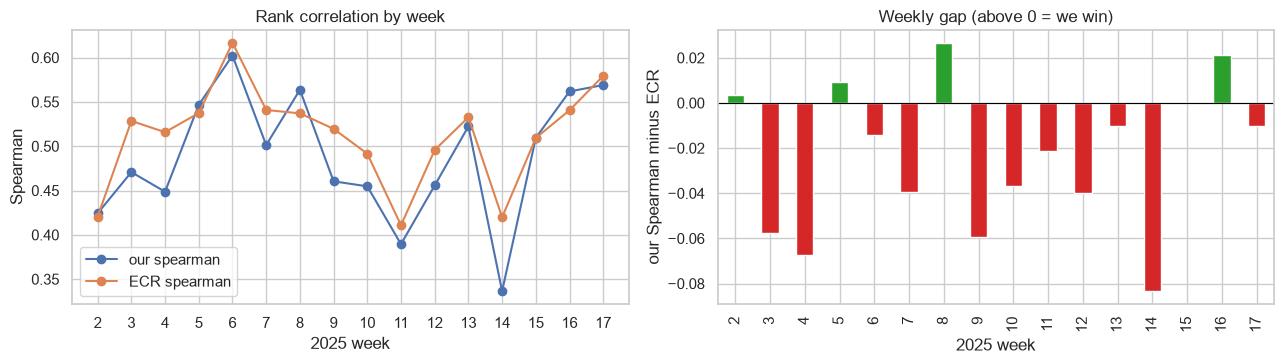

,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
our spearman,0.424,0.471,0.449,0.547,0.602,0.501,0.564,0.460,0.455,0.389,0.456,0.522,0.336,0.509,0.562,0.569
ECR spearman,0.421,0.529,0.516,0.537,0.617,0.541,0.537,0.520,0.492,0.411,0.496,0.533,0.420,0.509,0.541,0.579
our top-12 hit rate,0.521,0.458,0.479,0.521,0.604,0.583,0.500,0.521,0.521,0.479,0.500,0.562,0.479,0.562,0.583,0.542
ECR top-12 hit rate,0.500,0.500,0.438,0.542,0.583,0.521,0.604,0.542,0.500,0.458,0.521,0.542,0.438,0.521,0.458,0.562


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_week[["our spearman", "ECR spearman"]].plot(ax=axes[0], marker="o", xlabel="2025 week", ylabel="Spearman",
                                               title="Rank correlation by week")
axes[0].set_xticks(by_week.index)
weekly_gap.plot.bar(ax=axes[1], xlabel="2025 week", ylabel="our Spearman minus ECR", title="Weekly gap (above 0 = we win)",
                    color=np.where(weekly_gap > 0, "tab:green", "tab:red"))
axes[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
by_week[["our spearman", "ECR spearman", "our top-12 hit rate", "ECR top-12 hit rate"]].T.round(3)

**What we see:**
- The two lines move together: weeks that are hard for us are hard for the experts too (week 11: 0.389 and 0.411; week 14: 0.336 and 0.420).
- We are ahead in weeks 2, 5, 8, 15, and 16 (week 15 by less than 0.001). Our best week against them is week 8 (0.564 vs. 0.537).
- Our worst weeks against them are week 14 (-0.084), week 4 (-0.067), and week 9 (-0.060).
- On top-12 hit rate the picture flips: we are ahead in 10 of 16 weeks.

### 9.5 Players whose situation just changed
The experts read the news; our model only sees the situation features from section 5.4. So we split player-weeks by those flags.
Each player's rank error is how many places the predicted position rank is from the actual finish in that week (lower is better).

In [50]:
def add_rank_errors(rows):
    by_position_week = rows.groupby(["season", "week", "position"])
    actual_rank = by_position_week[TARGET].rank(ascending=False)
    return rows.assign(our_rank_error=(by_position_week["pred"].rank(ascending=False) - actual_rank).abs(),
                       ecr_rank_error=(by_position_week["ecr_pos_rank"].rank() - actual_rank).abs())


SITUATION_GROUPS = {
    "first game on a new team": lambda d: d["changed_team"] == 1,
    "starting QB out": lambda d: d["starting_qb_out"] == 1,
    "listed questionable": lambda d: d["questionable"] == 1,
    f"back after {RETURN_GAP_WEEKS}+ weeks out": lambda d: d["weeks_since_last_game"] >= RETURN_GAP_WEEKS,
}
ranked = add_rank_errors(head_to_head)
changed = pd.concat([flag(ranked) for flag in SITUATION_GROUPS.values()], axis=1).any(axis=1)
groups = {**{name: flag(ranked) for name, flag in SITUATION_GROUPS.items()},
          "any of the above": changed, "none of the above": ~changed}
situation_results = pd.DataFrame({
    name: {"player-weeks": mask.sum(),
           "our rank error": ranked.loc[mask, "our_rank_error"].mean(),
           "ECR rank error": ranked.loc[mask, "ecr_rank_error"].mean()}
    for name, mask in groups.items()}).T
situation_results["gap (ours minus ECR)"] = situation_results["our rank error"] - situation_results["ECR rank error"]
situation_results.round(2)

,player-weeks,our rank error,ECR rank error,gap (ours minus ECR)
first game on a new team,17.0,12.71,10.76,1.94
starting QB out,279.0,11.97,11.44,0.53
listed questionable,127.0,16.06,17.34,-1.28
back after 3+ weeks out,107.0,11.67,11.23,0.44
any of the above,466.0,12.53,12.41,0.12
none of the above,2559.0,12.34,12.12,0.23


**What we see:**
- 466 of the 3,025 player-weeks have at least one flag. For them our rank error is 12.53 places and the experts' is 12.41 (gap 0.12). For everyone else it is 12.34 vs. 12.12 (gap 0.23). So the experts' edge is not larger for flagged players.
- **By flag:** the experts are ahead when the starting QB is out (11.44 vs. 11.97) and for players back from 3 or more weeks out (11.23 vs. 11.67). The first game on a new team has the widest gap (12.71 for us vs. 10.76 for them) but only 17 player-weeks.
- **Questionable players** are the hardest group for both sides, and we are ahead there (16.06 vs. 17.34).
- We expected the experts to win mostly on news about changed situations. The data does not show that: their edge is spread thinly over all players.

### 9.6 Verdict
**We lose to the experts on ranking, by a small but consistent margin.**
- On the same 3,025 player-weeks of 2025, our weekly Spearman is 0.489 and ECR's is 0.512. The 95% interval for the weekly gap (-0.039 to -0.008) is below zero, so by the rule set before the test this is a loss, not a tie.
- On the top-12 hit rate we are slightly ahead (0.526 vs. 0.514, ahead in 10 of 16 weeks). So the experts order the whole list better, and we are about as good at picking who lands in the top 12.
- The experts' lead is largest at QB and in the first weeks of the season. TE is level.
- Our model does what it was built to do: it beats the last-3 baseline clearly (RMSE 6.83 vs. 7.72) and its 2025 scores are close to its CV scores. It gets most of the way to the experts using only public box-score, schedule, betting-line, and injury-report data.

Section 10 looks at why, and at who was right when we disagreed.

## 10. Analysis and wrap-up
Goal: explain the results. What drives our predictions, who was right when we and the experts disagreed, and what we conclude.

### 10.1 What drives our predictions
We shuffle one group of features at a time and measure how much the score drops. A big drop means the model leans on that group.
The frozen model is fit on 2020-2023 and scored on 2024, so 2025 is not touched. Groups are formed two ways: by feature family, and by how far back the stats look.

,columns,spearman drop,rmse rise
recent_production,8.0,0.2714,1.1119
usage,20.0,0.0878,0.3937
game_script,4.0,0.0237,0.0846
situation,9.0,0.0224,0.1225
position,4.0,0.0164,0.1324
opponent,1.0,0.0033,0.0134
luck,2.0,-0.0004,0.0014


,columns,spearman drop,rmse rise
recency-weighted (half-life 8 games),7.0,0.2059,0.8317
this season so far,7.0,0.0312,0.1566
last game,7.0,0.0261,0.1179
last 3 games,7.0,0.0034,0.0291
last season,2.0,0.0019,0.0202


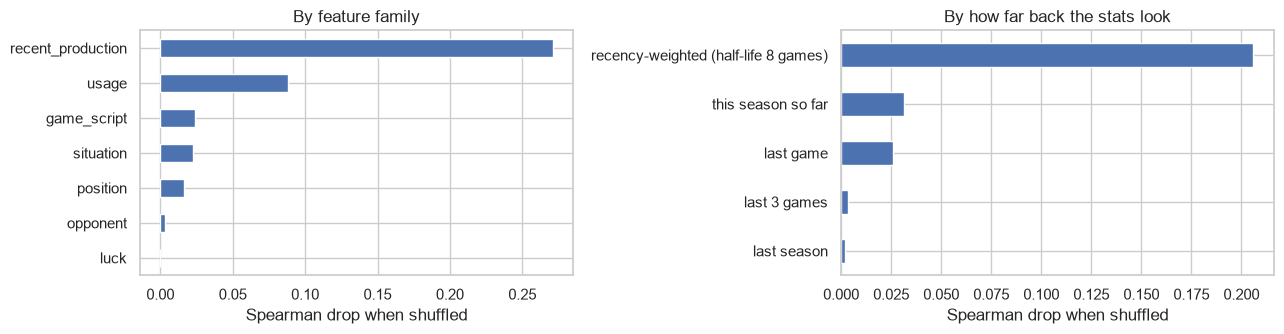

In [51]:
def shuffle_importance(model, rows, columns, groups, repeats=SHUFFLE_REPEATS):
    "Drop in score when each group of columns is shuffled across rows (averaged over a few shuffles)."
    base = evaluate(rows, model.predict(rows[columns]))
    rng = np.random.default_rng(SEED)
    results = {}
    for name, group in groups.items():
        drops = []
        for _ in range(repeats):
            shuffled = rows.copy()
            shuffled[group] = rows[group].to_numpy()[rng.permutation(len(rows))]
            score = evaluate(rows, model.predict(shuffled[columns]))
            drops.append({"spearman drop": base["spearman"] - score["spearman"], "rmse rise": score["rmse"] - base["rmse"]})
        results[name] = {"columns": len(group), **pd.DataFrame(drops).mean()}
    return pd.DataFrame(results).T.sort_values("spearman drop", ascending=False)


# Fit the frozen model on 2020-2023 and score it on 2024, the last CV season. 2025 is not used here.
last_cv_season = CV_VALID_SEASONS[-1]
model_features = frozen_choice["features"]
importance_rows = all_rows[all_rows["season"] == last_cv_season]
importance_model = fit_weighted(make_regression_model(frozen_choice),
                                all_rows[all_rows["season"].between(TRAIN_SEASONS[0], last_cv_season - 1)], model_features)

windowed_stats = [c.removesuffix("_last3") for c in model_features if c.endswith("_last3")]
TIME_WINDOWS = {"last game": "_last1", "last 3 games": "_last3",
                f"recency-weighted (half-life {HALF_LIFE} games)": "_recent", "this season so far": "_season"}
time_groups = {name: [stat + suffix for stat in windowed_stats] for name, suffix in TIME_WINDOWS.items()}
time_groups["last season"] = ["last_season_ppg", "no_last_season"]

family_importance = shuffle_importance(importance_model, importance_rows, model_features, FEATURE_FAMILIES)
window_importance = shuffle_importance(importance_model, importance_rows, model_features, time_groups)
display(family_importance.round(4), window_importance.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, table, title in [(axes[0], family_importance, "By feature family"),
                         (axes[1], window_importance, "By how far back the stats look")]:
    table["spearman drop"].sort_values().plot.barh(ax=ax, title=title, xlabel="Spearman drop when shuffled")
plt.tight_layout()
plt.show()

**What we see:**
- **Recent production drives everything.** Shuffling it drops Spearman by 0.271 (from 0.527) and raises RMSE by 1.11. Usage is second (0.088). The rest are small: game script 0.024, situation 0.022, position 0.016, opponent 0.003, luck about 0.
- **Recent vs. older games:** the recency-weighted averages matter most (drop 0.206). This season so far (0.031) and the last game (0.026) add a little. The last 3 games (0.003) and last season (0.002) add almost nothing once the others are known.
- So the model reads recent form, weighted toward the latest games but with older games still in it. This matches 5.7, where a half-life of 8 games beat both short windows and equal weights.
- **Caveat:** groups overlap (for example, last-3 and recency-weighted averages move together), so when one is shuffled the other can stand in. A small drop means "not needed on top of the rest", not "useless".

### 10.2 Who was right when we disagreed with the experts
We use the 2025 head-to-head rows from section 9 and rank players within each position-week for both sides.
A disagreement is a player-week where the two ranks are at least N places apart and one side has the player in its top 24
(the players people actually start). For each one we check whose rank was closer to the actual finish.

In [52]:
names = pd.read_parquet(PROCESSED_DIR / "player_weeks.parquet", columns=KEY + ["player_display_name"])
by_position_week = ranked.groupby(["season", "week", "position"])
both_ranks = ranked.assign(our_rank=by_position_week["pred"].rank(ascending=False),
                           ecr_rank=by_position_week["ecr_pos_rank"].rank(),
                           actual_rank=by_position_week[TARGET].rank(ascending=False),
                           rank_gap=lambda d: (d["our_rank"] - d["ecr_rank"]).abs())


def disagreements(rows, min_gap):
    "Player-weeks where the two rankings differ by min_gap or more places and one side has the player in its top 24."
    return rows[(rows["rank_gap"] >= min_gap) & (rows[["our_rank", "ecr_rank"]].min(axis=1) <= RELEVANT_RANK)]


def who_was_right(rows):
    return {"player-weeks": len(rows),
            "we were closer": (rows["our_rank_error"] < rows["ecr_rank_error"]).mean(),
            "experts were closer": (rows["ecr_rank_error"] < rows["our_rank_error"]).mean()}


both_top = both_ranks[(both_ranks["our_rank"] <= TOP_N) & (both_ranks["ecr_rank"] <= TOP_N)]
print(f"Agreement: weekly Spearman between our ranks and ECR's is "
      f"{by_position_week.apply(lambda w: w['pred'].corr(-w['ecr_pos_rank'], method='spearman')).mean():.3f}; "
      f"correlation of our rank errors with theirs is {both_ranks['our_rank_error'].corr(both_ranks['ecr_rank_error']):.3f}")
print(f"Shared misses: {len(both_top):,} player-weeks were in both top {TOP_N}s; "
      f"{(both_top['actual_rank'] > RELEVANT_RANK).mean():.1%} of them finished outside the top {RELEVANT_RANK}")

display(pd.DataFrame({f"{gap}+ places apart": who_was_right(disagreements(both_ranks, gap)) for gap in DISAGREE_GAPS}).T.round(3))
biggest = disagreements(both_ranks, DISAGREE_GAPS[-1]).nlargest(8, "rank_gap").merge(names, on=KEY)
biggest[["week", "player_display_name", "position", "our_rank", "ecr_rank", "actual_rank", TARGET,
         "games_this_season", "weeks_since_last_game", "questionable"]].round(1)

Agreement: weekly Spearman between our ranks and ECR's is 0.928; correlation of our rank errors with theirs is 0.891
Shared misses: 645 player-weeks were in both top 12s; 15.3% of them finished outside the top 24


,player-weeks,we were closer,experts were closer
6+ places apart,366.0,0.464,0.516
9+ places apart,153.0,0.484,0.503
12+ places apart,75.0,0.533,0.453


,week,player_display_name,position,our_rank,ecr_rank,actual_rank,fantasy_points_ppr,games_this_season,weeks_since_last_game,questionable
0,7,Emeka Egbuka,WR,7.0,84.0,28.5,9.8,6.0,1.0,1
1,16,Tee Higgins,WR,22.0,57.0,19.5,14.3,12.0,2.0,1
2,14,Tee Higgins,WR,9.0,43.0,4.0,27.2,11.0,2.0,0
3,7,Rashee Rice,WR,36.0,8.0,9.0,23.2,0.0,21.0,0
4,16,Drake London,WR,8.0,34.0,53.0,5.7,9.0,5.0,1
5,7,Quentin Johnston,WR,16.0,42.0,26.0,11.0,5.0,2.0,0
6,14,Adonai Mitchell,WR,49.0,23.0,53.0,3.4,11.0,1.0,0
7,15,CeeDee Lamb,WR,8.0,30.0,14.5,17.1,10.0,1.0,0


**What we see:**
- **We mostly agree with the experts.** Our ranks and theirs correlate at 0.928 within a position-week, and our misses line up with theirs (0.891). Of the 645 player-weeks both sides had in the top 12, 15.3% finished outside the top 24. Those shared misses are in-game injuries, blowouts, and normal weekly noise that no one can see coming.
- **When we disagree, it is close to a coin flip.** At 6+ places apart (366 player-weeks) the experts were closer 51.6% of the time and we were closer 46.4%. At 12+ places apart (75) it flips: we were closer 53.3%, they were closer 45.3%.
- **The experts win on news we cannot see.** Rashee Rice in week 7 was back from a suspension with no 2025 games. The experts ranked Rice 8th, we ranked Rice 36th, and Rice finished 9th. Drake London in week 16 was questionable and had not played in 4 weeks: they had London 34th, we had London 8th, and London finished 53rd.
- **We win when the experts react too strongly to an injury tag.** Emeka Egbuka (questionable, week 7) was 84th for them and 7th for us, and finished 28th. Tee Higgins in week 14 was 43rd for them and 9th for us, and finished 4th.
- So the experts' edge from section 9 is small and spread across many players. It is not won on a few big calls.

### 10.3 Conclusions
- **Main task:** our model predicts 2025 points with RMSE 6.83 and Spearman 0.505, close to its CV scores (6.77 and 0.525) and well ahead of the last-3 average (7.72 and 0.407).
- **Against the experts:** we lose on ranking order by a small, steady margin (Spearman 0.489 vs. 0.512) and are slightly ahead on top-12 hit rate (0.526 vs. 0.514). Their lead is largest at QB and early in the season.
- **Features matter more than the model.** Recent production and usage carry most of the signal. The tuned ensemble beats a plain Ridge by only 0.011 Spearman.
- **Recency:** recent games should count more inside the features (5.7), but older seasons should still count fully in training (6.4), and refitting every week adds almost nothing (9.2).
- **Extensions:** a tier classifier does not beat tiers cut from the regression (macro F1 0.454 vs. 0.495), so tiers are read off the points ranking. Usage clusters describe player roles well but add no predictive value.
- **Limits:** we use public data only, with no practice reports or beat news, and weekly points are noisy. Even the experts reach only 0.51 Spearman.

### 10.4 What we tried and didn't keep

| Idea | Why we dropped it |
|---|---|
| One model per position (section 6) | Per-position Ridge (Spearman 0.517) and boosting (0.510) were no better than one pooled model with position flags (0.515 and 0.519), with four times as many models to explain |
| Polynomial Lasso as a fourth member of the ensemble (section 6) | No gain over the three-member vote (Spearman 0.525 both ways) and much slower to fit |
| Stacking instead of voting (section 6.3) | Same score as the plain average (Spearman 0.5246 vs. 0.5247) with a second layer to explain |
| Training on only the last 1 to 3 seasons (section 6.4) | Never better than all seasons; last season only drops voting from 0.525 to 0.518 |
| Age weights on training rows, half-life 1 to 4 seasons (section 6.4) | Worse than equal weights for voting (0.521 to 0.524 vs. 0.525); the features already carry recency |
| Dropping the luck features (section 6) | Voting scored 0.524 without them vs. 0.525 with them, and Lasso already sets both to zero, so they stay |
| Pooled macro F1 for tiers (section 7) | It mixes positions and rewards knowing that QBs usually rank higher than WRs; tiers are compared within a position, so we score within each position-week |
| Unweighted tier classifiers (section 7.2) | Balanced class weights beat no weighting for every model and setting (+0.009 to +0.027 macro F1) |
| Equal-weight averages over the last 8 games (section 5.7) | Recency-weighted averages beat them at every half-life (Spearman 0.501 vs. 0.490 for Ridge) |
| Usage-cluster labels as model inputs (section 8.3) | Same Spearman (0.525) and slightly worse RMSE, so the clusters stay descriptive only |
| Raw tier labels from the classifier (section 7) | Macro F1 0.454 vs. 0.495 for tiers cut from the regression |

### 10.5 Societal impact
- **Betting:** fantasy rankings feed paid daily contests and sports betting. Our model loses to free expert rankings and weekly points are noisy (Spearman about 0.5), so it should not be sold or used as a betting edge.
- **Who gets ranked low:** the model judges players by past usage, so rookies, backups who just got a chance, and players back from injury are ranked worst. Anyone using it should check the news for those players first.
- **Player data:** we use only public box scores and the injury reports teams must publish. Injury status is health information about real people, so a tool like this should not guess at health beyond what is reported.